<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetectionICS_Cultice2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-kernel One-Class SVMs for ICS anomaly detection, three datasets and four feature maps: Cultice et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Tyler Cultice, Md. Saif Hassan Onim, Annarita Giani and Himanshu Thapliyal,
> "Quantum-Hybrid Support Vector Machines for Anomaly Detection in Industrial Control Systems",
> IEEE Transactions on Emerging Topics in Computing, 2025, arXiv:2506.17824 (https://arxiv.org/abs/2506.17824).

It is the journal extension of the group's ISVLSI 2024 paper (arXiv:2409.04935), whose single-dataset experiment is reproduced in
the sibling notebook `QSVM_AnomalyDetection_Cultice2024.ipynb`. The authors publish no code; everything below is written from the
method as the paper describes it, with the same software stack (Qiskit for circuits, Qiskit Aer for the noise study, PennyLane for the
kernel-target alignment, scikit-learn for the SVM).

**What is new compared with the 2024 paper.** (1) Three ICS datasets instead of one (SWaT, HAI 20.07, WADI); (2) three feature-reduction
methods (decision tree, PCA, non-negative matrix factorisation) instead of the decision tree only; (3) four quantum feature maps (Belis et al.,
a plain two-degrees-of-freedom rotation map, Sakhnenko et al.'s "Circuit 10", and the ZZ map) with 8, 12, 16 and 24 features instead of one map;
(4) three classical kernels (polynomial, RBF, linear) as comparators; (5) a noise study with density-matrix simulations of IBM Kyiv,
Sherbrooke and Torino; (6) kernel-target alignment as a "quantum advantage" indicator.

**What the notebook does.** It downloads the public ICS data, applies the paper's 60-sample moving average, reduces the sensors to `N`
features, loads two features per qubit into a fidelity kernel `K(x, y) = |<phi(x)|phi(y)>|^2`, post-processes it as `exp(K)` and trains a
precomputed One-Class SVM on normal windows only. It sweeps the paper's grid (dataset x reduction x feature count x feature map),
runs the three classical kernels on the same reduced inputs, re-draws the paper's Figs. 7 to 10, repeats the headline configurations
over several seeds, computes kernel-target alignment (Table V), simulates hardware noise (Tables III and IV) and puts every number of the
paper next to ours with a verdict.

**Important substitution.** SWaT and WADI are only distributed by the iTrust centre (SUTD) after an access request, so they cannot be
downloaded inside a notebook. They are replaced by two public datasets (HAI 21.03 for the water-treatment role and BATADAL for the
water-distribution role); HAI 20.07, the paper's third dataset, is used as is. Numbers for the substitutes are therefore **not** comparable
one-to-one with the paper's SWaT and WADI columns, and every verdict says so.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. With `FAST_MODE = True` (small samples,
8 and 12 features, a small noise study) it finishes in about 10 minutes; with `FAST_MODE = False` it uses the paper-scale grid
(runtime stated in the configuration cell). Data (about 190 MB of compressed CSV) is downloaded on the first run.

**What you get at the end.** Results tables and figures mirroring the paper's Figs. 7 to 10 and Tables III to VI, honest selection of
hyper-parameters on a validation block (plus the paper's test-set "best nu" for comparison), and a verdict on each claim.

## The paper in one page

**Problem.** Sensors and actuators of industrial control systems (ICS) are read by SCADA software that raises rule-based alarms; the
paper argues these are not enough and proposes machine-learned *anomaly detection*: decide for each time step whether the sensor vector is
normal or attacked.

**Decision.** Binary normal / anomalous. The model is a **One-Class SVM** (OCSVM, Section IV-C) trained on normal data; test windows with a
negative decision value are called anomalies.

**Method.**
1. Moving average over 60 overlapping samples (Eq. for `mat`), z-score standardisation (Eq. 3), then feature reduction to `N` features by
   (a) decision-tree Gini importance, (b) PCA, or (c) NMF, with `N = 8, 12, 16, 24` (ZZ only `8, 12, 16`). "Applied separately to the train
   set and test set to avoid data leakage."
2. `N` features are loaded onto `N/2` qubits with two degrees of freedom per qubit ("dense angle encoding"), data scaled to `[-pi, pi]`, bandwidth
   considered; feature maps repeated 1 to 3 times. Four maps: **Belis et al.** (U gates, nearest-neighbour entanglement, second rotation),
   **2DoF** (only the U gates, no entanglement), **Sakhnenko et al.** (Circuit 10 from Rx, Ry, CNOT, `theta = pi/2`), **ZZ** (Qiskit
   `ZZFeatureMap`, `N` qubits).
3. Fidelity kernel by the compute-uncompute test (Fig. 1), `K(x, y) = |<phi(x)|phi(y)>|^2`, post-processed `exp(K)`; precomputed OCSVM.
   `nu` and the tolerance are "swept and best results selected" for quantum and classical alike.
4. Classical comparators: polynomial, RBF, linear kernels on the same reduced data (Fig. 10).
5. Noise: Qiskit Aer density-matrix simulation with noise snapshots of IBM Kyiv, Sherbrooke, Torino (Table II) for Belis and 2DoF at `N = 8, 12, 16`.
6. Quantum advantage: kernel-target alignment (PennyLane) of quantum and classical kernels (Table V).

**Data.** SWaT (water treatment, 2015, 51 sensors/actuators, 41 attacks), HAI 20.07 (59 features, 38 attacks, 177 h normal training data),
WADI (water distribution, 2017, 123 sensors/actuators, 15 attacks). "Up to 24 features and 2000 windowed and processed data points each."

**Claims (numbers we can test).**

| Claim | Paper |
|---|---|
| Best SWaT model (Table VI) | 2DoF, 12 tree features: precision / recall / F1 = 0.95 / 0.95 / 0.95 (text says 16 features) |
| Best HAI model | Belis, 16 tree features: 0.88 / 0.87 / 0.86 (identical to the 2024 paper's Table I row) |
| Best WADI model | 2DoF, 16 tree features: 0.90 / 0.88 / 0.88 (text: 0.90 / 0.89 / 0.89) |
| Best classical kernel | SWaT: RBF + tree, recall 0.91, F1 0.89 (classical average F1 0.88); HAI: 0.77 / 0.79 / 0.78 (poly or linear + tree); WADI: average F1 0.722 |
| Quantum beats classical | on average +13.3 % F1; HAI +4.6 % precision, +9.8 % recall, +11.8 % F1; SWaT about 6 % on average; WADI best 13 % |
| Pre-processing | tree is best for quantum kernels, NMF is poor for both, PCA poor for Belis/2DoF/Sakhnenko on HAI but fine for ZZ |
| Entanglement | not needed: the plain 2DoF map equals or beats Belis and Sakhnenko; ZZ is least consistent |
| Noise (Table III, IV) | kernel dissimilarity `1 - KA(K_ideal, K_noisy)` at most 0.98 % (9.8e-3); average drop of classification metrics 1.57 %; Torino (highest readout error) worst; Belis more affected than 2DoF |
| Kernel-target alignment (Table V) | quantum minus classical = +0.048 on average, "91.023 % improvement" |

## What follows the paper and what had to be chosen

The paper is a journal article without code and leaves many details open. Every choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| SWaT | iTrust SWaT | **not downloadable**; stand-in: HAI 21.03 (train1 normal; test1 + test2 labelled), the second public HAI release (same testbed family, other attacks, 79 sensors) |
| HAI | HAI 20.07 | HAI 20.07 from the authors' GitHub repository (train1, train2, test1, test2) |
| WADI | iTrust WADI | **not downloadable**; stand-in: BATADAL (C-Town water-distribution network, 43 hourly sensors; dataset 3 = normal year, dataset 4 = 7 attacks, attack hours flagged) |
| Moving average | 60 overlapping samples | 60 samples (1 Hz) for both HAI sets; **6 samples** for BATADAL because it is sampled hourly and attacks last 4 to 100 hours |
| Window label | not stated | label of the last sample; normal-labelled windows that touch an attack are dropped |
| Feature ranking (tree) | Gini importance; labelled data not stated | tree on a labelled **calibration block** (first 40 % of the first labelled file, 60 % for BATADAL); the block is never used for testing |
| PCA / NMF | "applied separately to train and test" | fitted on the **training windows only**, applied to validation and test; NMF on min-max scaled data (non-negativity) |
| Feature maps | Figs. 4 to 6 (no gate parameters) | Belis: `U(x2q, x2q+1, 0)` - CNOT chain - `RY(x2q) RZ(x2q+1)`, x3 repetitions; 2DoF: `U(x2q, x2q+1, 0)` once; Sakhnenko: `RY(pi/2)` - CNOT ring - `RX(x2q) RY(x2q+1)`; ZZ: Qiskit `zz_feature_map(N, reps=2, "linear")` |
| Encoding of "U(pi/2, phi, lambda)" | text of Section IV-B1 | dense angle encoding `U(theta=x2q, phi=x2q+1, 0)`; the literal `U(pi/2, phi, lambda)` acting on `|0>` cannot depend on `lambda` (Section 5b shows this) |
| Data scaling / bandwidth | `[-pi, pi]`, bandwidth "considered" | z-score times bandwidth `bw`, clipped to `[-pi, pi]`; `bw` tuned on a validation block |
| Kernel post-processing | `exp(K)` | same |
| `nu`, tolerance | swept, "best results selected" | `nu` swept; **two numbers are reported**: `nu` chosen on a validation block (honest) and best `nu` on the test set (what the paper describes, optimistic); tolerance left at the scikit-learn default |
| Classical kernels | poly, RBF, linear (parameters not stated) | poly `(g<x,y>+1)^3`, RBF, linear; `g` tuned on the validation block with the same budget |
| Train / test sizes | "up to 2000 windowed points", split not stated | 600 normal training windows; test 600 normal + 300 anomalous (BATADAL: at most 80 % of the attack windows, 2 normals each) |
| Metrics | precision, recall, F1 | weighted averages over the two classes (the paper's Table VI has recall = accuracy in the 2024 paper), plus attack-class F1 and ROC-AUC |
| Noise | IBM Kyiv / Sherbrooke / Torino snapshots of 2024/25 | `FakeKyiv`, `FakeSherbrooke`, `FakeTorino` calibration snapshots shipped with qiskit-ibm-runtime (other dates than the paper's Table II); density-matrix Aer simulation; 8192 shots; small sample because every kernel entry is a separate circuit |
| Kernel-target alignment | PennyLane `target_alignment` | the same formula in numpy, checked against `qml.kernels.target_alignment`, on the labelled validation draw with tuned hyper-parameters |
| Seeds, repetitions | not stated | `SEED = 42`; grid with one split (as in the paper), headline configurations repeated over seeds |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning / pennylane are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("pennylane") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "pennylane==0.45.1" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-machine-learning and pennylane already present; skipping pip install.")

qiskit, qiskit-machine-learning and pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False       # True: class demo (8 and 12 features, small samples, small noise study), about 10 min on a CPU.
                        # False: paper-scale grid (8/12/16/24 features, 600 training windows, 5 seeds, 3 noise backends); about 110 min on a shared CPU (3 datasets, 126+ grid cells, 36 noisy-kernel experiments).
SEED      = 42          # CHOICE: the paper gives no seed
IBM_TOKEN = ""          # unused: the paper simulates IBM noise models, so the fake backends of qiskit-ibm-runtime are enough; no hardware is touched

DATA_DIR  = "ics_data"  # cache folder for the downloaded files (relative to the working directory)

DATASETS     = ("HAI20.07", "HAI21.03", "BATADAL")      # roles: paper's HAI, stand-in for SWaT, stand-in for WADI
REDUCTIONS   = ("Tree", "NMF", "PCA")                    # paper Section IV-A
FEATURE_MAPS = ("Belis", "2DoF", "Sakhnenko", "ZZ")      # paper Section IV-B
CLASSICAL    = ("poly", "rbf", "linear")                 # paper Fig. 10
NU_GRID      = (0.001, 0.003, 0.01, 0.03, 0.1, 0.2)      # CHOICE: nu sweep (paper: "swept")

if FAST_MODE:
    N_LIST   = (8, 12);          ZZ_MAX_N = 12
    N_TRAIN  = 250                                       # normal windows the OCSVM is trained on
    N_TEST_NORMAL, N_TEST_ANOM = 400, 200                # test composition 2:1 (BATADAL: capped by the number of attack windows)
    N_VAL_NORMAL,  N_VAL_ANOM  = 300, 150                # validation draw from the calibration block
    TUNE_N_TRAIN, TUNE_N_VAL = 120, 150                  # sub-sample used to pick the bandwidth
    BW_GRID  = (0.03, 0.1, 0.3)
    GAMMA_MULTS = (0.3, 1.0, 3.0)
    ZZ_BIG_QUBITS, ZZ_BIG_TRAIN, ZZ_BIG_TEST = 12, 250, 400
    N_SEEDS  = 2
    KTA_N    = 8
    N_NATURAL = 1500                                     # windows at the natural anomaly rate
    NOISE_DATASETS, NOISE_N, NOISE_BACKENDS = ("HAI20.07",), (8,), ("FakeTorino",)
    NOISE_NTR, NOISE_NTE_NORM, NOISE_NTE_ANOM = 16, 16, 8
else:
    N_LIST   = (8, 12, 16, 24);  ZZ_MAX_N = 16
    N_TRAIN  = 600
    N_TEST_NORMAL, N_TEST_ANOM = 600, 300
    N_VAL_NORMAL,  N_VAL_ANOM  = 300, 150
    TUNE_N_TRAIN, TUNE_N_VAL = 150, 150
    BW_GRID  = (0.02, 0.05, 0.1, 0.2, 0.4, 0.8)
    GAMMA_MULTS = (0.1, 0.3, 1.0, 3.0, 10.0)
    ZZ_BIG_QUBITS, ZZ_BIG_TRAIN, ZZ_BIG_TEST = 12, 200, 300   # 16-qubit statevectors (65536 amplitudes) are sub-sampled to fit in memory
    N_SEEDS  = 5
    KTA_N    = 16
    N_NATURAL = 4000
    NOISE_DATASETS, NOISE_N, NOISE_BACKENDS = DATASETS, (8, 12), ("FakeKyiv", "FakeSherbrooke", "FakeTorino")
    NOISE_NTR, NOISE_NTE_NORM, NOISE_NTE_ANOM = 20, 20, 10

NOISE_SHOTS   = 8192        # CHOICE: shots per noisy fidelity circuit (the paper does not state it)
NOISE_NU      = 0.1         # CHOICE: fixed nu for the tiny noise-study samples
NOISE_THREADS = 4           # parallel Aer experiments (the machine is shared; raise on a free multi-core runtime)
REPS_BELIS    = 3           # paper: "we repeat the gates of this feature map up to three times"
REPS_ZZ       = 2           # Qiskit default of ZZFeatureMap

In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, scipy
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import OneClassSVM
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED              # Qiskit-ML global seed (no stochastic step in the exact kernels, kept for completeness)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
try:
    import pennylane as qml
    print("pennylane", qml.__version__)
except Exception as exc:                          # the KTA cross-check is skipped if PennyLane is missing
    qml = None; print("pennylane not available:", exc)
try:
    import qiskit_aer, qiskit_ibm_runtime
    print("qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)
except Exception as exc:
    print("noise study unavailable:", exc)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


pennylane 0.45.1


qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


## 1. The three datasets

| Role in the paper | Paper | Used here | Why |
|---|---|---|---|
| Water treatment | SWaT (iTrust, SUTD) | **HAI 21.03** | SWaT needs an access request; HAI 21.03 is the next public release of the HAI testbed (79 sensors, 1 Hz, 5 labelled test files) |
| Hydro / steam power | HAI 20.07 | **HAI 20.07** | public, exactly as in the paper |
| Water distribution | WADI (iTrust, SUTD) | **BATADAL** | WADI needs an access request; BATADAL (Taormina et al. 2018) is a public water-distribution data set with labelled attacks |

**HAI** (Shin et al.): a hardware-in-the-loop testbed with a boiler (P1), a turbine (P2), a water-treatment tank system (P3) and a power-grid
simulation (P4); training files contain only normal operation, test files contain labelled attacks. **BATADAL**: the simulated C-Town water network
with 7 pumping stations, 43 hourly sensor values (tank levels, pump flows and statuses, junction pressures); *dataset 3* is one attack-free year;
*dataset 4* is a partly labelled stretch of 4177 hours in which attack hours carry `ATT_FLAG = 1` and all others `-999`. We treat `-999` as
"not flagged = normal"; the competition description does not guarantee that no unflagged attack is hidden among them.

In [4]:
SPEC = {
    "HAI20.07": dict(kind="hai", ver="20.07", sep=";", train=["train1", "train2"], lab=["test1", "test2"], window=60, cal=0.40,
                     role="HAI (the paper's own dataset)"),
    "HAI21.03": dict(kind="hai", ver="21.03", sep=",", train=["train1"], lab=["test1", "test2"], window=60, cal=0.40,
                     role="stand-in for SWaT (water treatment)"),
    "BATADAL":  dict(kind="batadal", window=6, cal=0.60, role="stand-in for WADI (water distribution)"),   # CHOICE: hourly data -> 6-sample average, 60 % calibration block
}
HAI_URLS = [  # CHOICE: three public mirrors of the same files, tried in this order
    "https://raw.githubusercontent.com/icsdataset/hai/master/hai-{ver}/{f}.csv.gz",
    "https://media.githubusercontent.com/media/icsdataset/hai/master/hai-{ver}/{f}.csv.gz",
    "https://cdn.jsdelivr.net/gh/icsdataset/hai@master/hai-{ver}/{f}.csv.gz",
]
BATADAL_URLS = ["https://www.batadal.net/data/{f}", "https://batadal.net/data/{f}"]

def _download(urls, dest, valid):
    if os.path.exists(dest) and valid(dest):
        return dest
    for url in urls:
        try:
            with requests.get(url, stream=True, timeout=180, headers={"User-Agent": "Mozilla/5.0"}) as r:
                r.raise_for_status()
                with open(dest, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            if valid(dest):
                print(f"  {os.path.basename(dest)}: downloaded from {url} ({os.path.getsize(dest)/1e6:.1f} MB)")
                return dest
            print(f"  {os.path.basename(dest)}: {url} did not return a valid file (Git-LFS pointer?), trying next mirror")
        except Exception as exc:
            print(f"  {os.path.basename(dest)}: {url} failed ({type(exc).__name__}: {exc}), trying next mirror")
    raise RuntimeError(f"Could not obtain {os.path.basename(dest)}. Download it by hand (HAI: https://github.com/icsdataset/hai , "
                       f"BATADAL: https://www.batadal.net/data.html) and place it in '{DATA_DIR}' under that name.")

def load_raw(name):
    """Returns (sensor column names, list of (sensor DataFrame, attack labels) for training, same for labelled test data)."""
    sp = SPEC[name]
    if sp["kind"] == "hai":
        def read(f):
            dest = os.path.join(DATA_DIR, f"hai{sp['ver']}_{f}.csv.gz")
            ok = lambda p: ("attack" in pd.read_csv(p, sep=sp["sep"], nrows=2).columns)
            _download([u.format(ver=sp["ver"], f=f) for u in HAI_URLS], dest, ok)
            return pd.read_csv(dest, sep=sp["sep"])
        tr = [read(f) for f in sp["train"]]; lab = [read(f) for f in sp["lab"]]
        sensors = [c for c in tr[0].columns if c not in ("time", "attack", "attack_P1", "attack_P2", "attack_P3")]
        return sensors, [(d[sensors], d["attack"].to_numpy()) for d in tr], [(d[sensors], d["attack"].to_numpy()) for d in lab]
    def read_b(f):
        dest = os.path.join(DATA_DIR, f)
        ok = lambda p: ("ATT_FLAG" in pd.read_csv(p, nrows=2).rename(columns=str.strip).columns)
        _download([u.format(f=f) for u in BATADAL_URLS], dest, ok)
        d = pd.read_csv(dest); d.columns = [c.strip() for c in d.columns]; return d
    b3, b4 = read_b("BATADAL_dataset03.csv"), read_b("BATADAL_dataset04.csv")
    sensors = [c for c in b3.columns if c not in ("DATETIME", "ATT_FLAG")]
    return sensors, [(b3[sensors], np.zeros(len(b3), int))], [(b4[sensors], (b4["ATT_FLAG"].to_numpy() == 1).astype(int))]

t0 = time.time(); RAW = {}
for name in DATASETS:
    print(f"{name}: {SPEC[name]['role']}")
    RAW[name] = load_raw(name)
print(f"loaded in {time.time()-t0:.0f} s")
rows = []
for name in DATASETS:
    sensors, tr, lab = RAW[name]
    rows.append(dict(dataset=name, role=SPEC[name]["role"], sensors=len(sensors), train_rows=sum(len(x) for x, _ in tr),
                     labelled_rows=sum(len(x) for x, _ in lab), attack_rows=int(sum(y.sum() for _, y in lab)),
                     attack_pct=round(100 * sum(y.sum() for _, y in lab) / sum(len(x) for x, _ in lab), 2)))
display(pd.DataFrame(rows))

HAI20.07: HAI (the paper's own dataset)


HAI21.03: stand-in for SWaT (water treatment)


BATADAL: stand-in for WADI (water distribution)
loaded in 36 s


,dataset,role,sensors,train_rows,labelled_rows,attack_rows,attack_pct
0,HAI20.07,HAI (the paper's own dataset),59,550800,444600,17527,3.94
1,HAI21.03,stand-in for SWaT (water treatment),79,216001,162002,4078,2.52
2,BATADAL,stand-in for WADI (water distribution),43,8761,4177,219,5.24


## 2. Pre-processing: moving average, histogram values, z-score

Following Section IV-A of the paper, separately for every file (so no window crosses a file boundary):

1. **Moving average** over `WINDOW` consecutive samples, `m_t = (1/w) * sum_{i=t-w+1..t} x_i` (60 s for the HAI sets, 6 h for BATADAL).
2. **Categorical columns** (at most ten distinct values: switches, pump statuses) are replaced by their relative frequency in the normal training data
   *before* averaging (the 2024 paper's "histogram values"). # CHOICE
3. **Standardisation** `(x - mean)/std` with the statistics of the **normal training windows only**.

A window is labelled by its **last** sample (what a real-time detector would decide); normal-labelled windows that still contain attack samples are dropped. # CHOICE
The normal training pool, a **labelled calibration block** (the first part of the first labelled file in time: used to rank sensors with the decision tree and to
draw validation data) and an **evaluation pool** (everything after it) are kept strictly disjoint; test windows are only ever drawn from the evaluation pool.

In [5]:
DATA = {}
def build_dataset(name):
    sp = SPEC[name]; sensors, tr, lab = RAW[name]; W = sp["window"]
    cat_cols = [c for c in sensors if tr[0][0][c].nunique() <= 10]                               # CHOICE: <= 10 distinct values = categorical
    freq = {c: tr[0][0][c].value_counts(normalize=True).to_dict() for c in cat_cols}
    def windows(df, att):
        d = df[sensors].copy()
        for c in cat_cols: d[c] = d[c].map(freq[c]).fillna(0.0)
        X = d.rolling(W).mean().iloc[W - 1:].to_numpy(dtype=np.float32)
        y = att[W - 1:]; any_att = pd.Series(att).rolling(W).max().to_numpy()[W - 1:]
        keep = ~((any_att == 1) & (y == 0))                                                      # CHOICE: drop normal windows that touch an attack
        return X[keep], y[keep].astype(int)
    pool = []
    for df, att in tr:
        X, y = windows(df, att); pool.append(X[y == 0])
    pool = np.vstack(pool)
    mu = pool.mean(axis=0, dtype=np.float64); sd = pool.std(axis=0, dtype=np.float64); sd[sd == 0] = 1.0
    Z = lambda X: (np.asarray(X, dtype=np.float64) - mu) / sd
    labw = [windows(df, att) for df, att in lab]
    n_cal = int(sp["cal"] * len(labw[0][0]))
    Xc, yc = labw[0][0][:n_cal], labw[0][1][:n_cal]
    Xe = np.vstack([labw[0][0][n_cal:]] + [w[0] for w in labw[1:]]); ye = np.concatenate([labw[0][1][n_cal:]] + [w[1] for w in labw[1:]])
    dt = DecisionTreeClassifier(random_state=SEED, class_weight="balanced").fit(Z(Xc), yc)       # CHOICE: balanced classes, full depth
    imp = dt.feature_importances_
    return dict(sensors=sensors, cat_cols=cat_cols, pool=pool, mu=mu, sd=sd, Z=Z, Xc=Xc, yc=yc, Xe=Xe, ye=ye,
                cal_norm=np.flatnonzero(yc == 0), cal_att=np.flatnonzero(yc == 1), ev_norm=np.flatnonzero(ye == 0), ev_att=np.flatnonzero(ye == 1),
                rank=np.argsort(-imp, kind="stable"), imp=imp)

t0 = time.time()
for name in DATASETS:
    DATA[name] = build_dataset(name)
rows = []
for name, D in DATA.items():
    rows.append(dict(dataset=name, window=SPEC[name]["window"], categorical_cols=len(D["cat_cols"]), normal_pool=len(D["pool"]),
                     calib_windows=len(D["Xc"]), calib_anom=len(D["cal_att"]), eval_windows=len(D["Xe"]), eval_anom=len(D["ev_att"]),
                     eval_anom_pct=round(100 * len(D["ev_att"]) / len(D["Xe"]), 2), tree_nonzero_sensors=int((D["imp"] > 0).sum())))
display(pd.DataFrame(rows)); print(f"windowed in {time.time()-t0:.0f} s")

# test / validation sizes: the paper's 2:1 normal:anomalous mix, capped by what each data set offers
SIZES = {}
for name, D in DATA.items():
    ta = min(N_TEST_ANOM, int(0.8 * len(D["ev_att"]))); va = min(N_VAL_ANOM, int(0.6 * len(D["cal_att"])))
    SIZES[name] = dict(te_a=ta, te_n=min(2 * ta, len(D["ev_norm"])), va_a=va, va_n=min(2 * va, len(D["cal_norm"])))
print(pd.DataFrame(SIZES).T)

,dataset,window,categorical_cols,normal_pool,calib_windows,calib_anom,eval_windows,eval_anom,eval_anom_pct,tree_nonzero_sensors
0,HAI20.07,60,10,549788,115955,4352,326285,13175,4.04,49
1,HAI21.03,60,24,215942,17138,480,143271,3598,2.51,15
2,BATADAL,6,16,8756,2488,102,1659,117,7.05,23


windowed in 34 s
          te_a  te_n  va_a  va_n
HAI20.07   300   600   150   300
HAI21.03   300   600   150   300
BATADAL     93   186    61   122


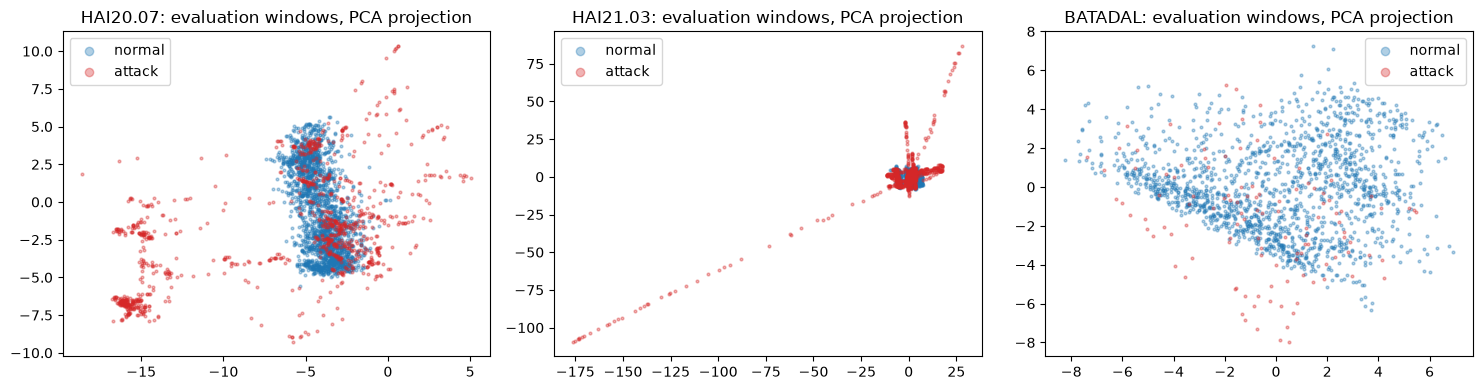

In [6]:
# The paper's Fig. 2 shows a UMAP of the test data. UMAP is not needed for anything else here, so we draw a linear PCA projection instead:
# normal evaluation windows (blue) against attack windows (red), after the same pre-processing.
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 4))
for a, name in zip(np.atleast_1d(ax), DATASETS):
    D = DATA[name]; p = PCA(2, random_state=SEED).fit(D["Z"](D["pool"][::max(1, len(D["pool"]) // 5000)]))
    r = np.random.default_rng(SEED)
    n_idx = r.choice(D["ev_norm"], min(2000, len(D["ev_norm"])), replace=False); a_idx = r.choice(D["ev_att"], min(1000, len(D["ev_att"])), replace=False)
    Pn, Pa = p.transform(D["Z"](D["Xe"][n_idx])), p.transform(D["Z"](D["Xe"][a_idx]))
    a.scatter(Pn[:, 0], Pn[:, 1], s=4, alpha=.35, c="tab:blue", label="normal"); a.scatter(Pa[:, 0], Pa[:, 1], s=4, alpha=.35, c="tab:red", label="attack")
    a.set_title(f"{name}: evaluation windows, PCA projection"); a.legend(markerscale=3)
plt.tight_layout(); plt.show()

## 3. Feature reduction: decision tree, PCA, NMF

The paper keeps `N` features, with `N = 8, 12, 16, 24`, one pair of features per qubit.

* **Tree**: the `N` sensors with the largest Gini importance in a decision tree fitted on the labelled calibration block (the tree needs labels; the paper does
  not say which; see the discussion of leakage in the 2024 notebook).
* **PCA**: `N` principal components, fitted on the training windows (normal data only).
* **NMF**: `N` non-negative factors of the min-max-scaled training windows (NMF needs non-negative input; test windows are scaled with the training minima and maxima and clipped to `[0, 1]`).

After the reduction every feature is standardised again with training statistics. The quantum model then multiplies by a **bandwidth** `bw`
and clips to `[-pi, pi]` to obtain rotation angles; the classical kernels use the standardised features directly.

In [7]:
_split_cache, _feat_cache = {}, {}

def get_split(name, seed=0, tag="paper"):
    """Raw (not yet standardised) windows: training (normal), validation (from the calibration block), test (from the evaluation pool)."""
    key = (name, seed, tag)
    if key in _split_cache: return _split_cache[key]
    D, sz = DATA[name], SIZES[name]
    tr = np.random.default_rng(SEED + seed).choice(len(D["pool"]), N_TRAIN, replace=False)
    r = np.random.default_rng(SEED + 1000 + seed)
    va_n, va_a = r.choice(D["cal_norm"], sz["va_n"], replace=False), r.choice(D["cal_att"], sz["va_a"], replace=False)
    r = np.random.default_rng(SEED + 500 + seed)
    if tag == "paper":          # the paper-style mix: normal windows first, then anomalous ones
        te_n, te_a = r.choice(D["ev_norm"], sz["te_n"], replace=False), r.choice(D["ev_att"], sz["te_a"], replace=False)
        te = np.r_[te_n, te_a]
    else:                       # natural anomaly rate
        te = r.choice(len(D["Xe"]), min(N_NATURAL, len(D["Xe"])), replace=False)
    S = dict(Xtr=D["pool"][tr], Xva=np.vstack([D["Xc"][va_n], D["Xc"][va_a]]), yva=np.r_[np.zeros(len(va_n), int), np.ones(len(va_a), int)],
             Xte=D["Xe"][te], yte=D["ye"][te])
    _split_cache[key] = S; return S

def get_features(name, red, N, seed=0, tag="paper"):
    key = (name, red, N, seed, tag)
    if key in _feat_cache: return _feat_cache[key]
    D, S = DATA[name], get_split(name, seed, tag)
    Ztr, Zva, Zte = D["Z"](S["Xtr"]), D["Z"](S["Xva"]), D["Z"](S["Xte"])
    if red == "Tree":
        sel = D["rank"][:N]; Ftr, Fva, Fte = Ztr[:, sel], Zva[:, sel], Zte[:, sel]
    elif red == "PCA":
        p = PCA(n_components=N, random_state=SEED).fit(Ztr); Ftr, Fva, Fte = p.transform(Ztr), p.transform(Zva), p.transform(Zte)
    elif red == "NMF":
        mm = MinMaxScaler().fit(S["Xtr"]); f = lambda X: np.clip(mm.transform(X), 0, 1)
        nmf = NMF(n_components=N, init="nndsvda", max_iter=500, random_state=SEED).fit(f(S["Xtr"]))      # CHOICE: nndsvda init, 500 iterations
        Ftr, Fva, Fte = nmf.transform(f(S["Xtr"])), nmf.transform(f(S["Xva"])), nmf.transform(f(S["Xte"]))
    else:
        raise ValueError(red)
    m, s = Ftr.mean(axis=0), Ftr.std(axis=0); s[s == 0] = 1.0
    out = dict(tr=(Ftr - m) / s, va=(Fva - m) / s, te=(Fte - m) / s)
    _feat_cache[key] = out; return out

# quick look: the ten sensors the tree likes most, per dataset
for name in DATASETS:
    D = DATA[name]
    print(f"{name}: top-8 Gini sensors:", ", ".join(f"{D['sensors'][i]} ({D['imp'][i]:.2f})" for i in D["rank"][:8]))

HAI20.07: top-8 Gini sensors: P1_LCV01D (0.28), P1_PIT01 (0.11), P2_VXT03 (0.07), P2_SIT01 (0.06), P2_VXT02 (0.05), P1_FCV02Z (0.04), P3_LT01 (0.04), P1_B3005 (0.04)
HAI21.03: top-8 Gini sensors: P1_TIT01 (0.51), P1_FT01Z (0.22), P1_LIT01 (0.07), P3_LIT01 (0.07), P1_TIT02 (0.05), P1_B4005 (0.03), P1_PCV01Z (0.03), P4_ST_TT01 (0.01)
BATADAL: top-8 Gini sensors: L_T1 (0.28), F_PU11 (0.25), P_J269 (0.12), F_PU1 (0.11), F_V2 (0.11), P_J317 (0.04), F_PU4 (0.03), P_J422 (0.02)


## 4. The four quantum feature maps (paper Figs. 4 to 6)

Each of the first three maps loads **two** features per qubit ("dense angle encoding"): `N` features need `N/2` qubits. The ZZ map uses one feature per qubit.

| Map | Circuit (per qubit unless stated) | Entanglement | Repetitions |
|---|---|---|---|
| **Belis** (Fig. 4) | `U(x_2q, x_2q+1, 0)`, then CNOT chain, then `RY(x_2q) RZ(x_2q+1)` | nearest neighbour | 3 |
| **2DoF** (reference) | `U(x_2q, x_2q+1, 0)` only | none | 1 |
| **Sakhnenko** (Fig. 5, "Circuit 10" with `theta = pi/2`) | `RY(pi/2)`, then CNOT ring, then `RX(x_2q) RY(x_2q+1)` | ring | 1 |
| **ZZ** (Fig. 6) | `H`, `P(2 x_i)`, `CX P(2 (pi-x_i)(pi-x_j)) CX` on neighbours; Qiskit `zz_feature_map` | linear | 2 |

`# CHOICE:` The figures in the paper carry no gate parameters. Belis reuses the circuit of the 2024 paper. For Sakhnenko the fixed `theta = pi/2` gates come
**before** the data-dependent rotations: a data-independent gate *after* the encoding cancels in the fidelity `|<0|U(y)^dagger U(x)|0>|^2` (try it in Exercise 2), so
such a circuit would be exactly the product encoding.

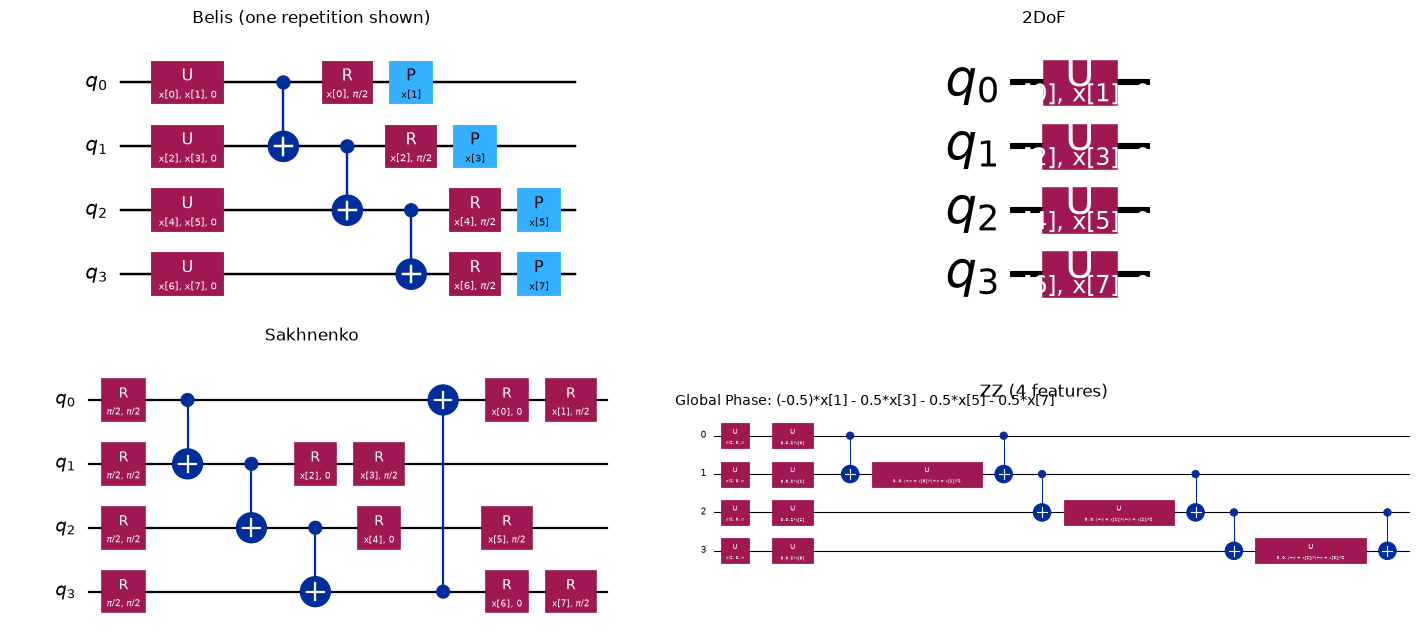

In [8]:
def _ring(n):
    return [(q, q + 1) for q in range(n - 1)] + ([(n - 1, 0)] if n > 2 else [])

def qc_belis(N, reps=REPS_BELIS):
    nq = N // 2; x = ParameterVector("x", N); qc = QuantumCircuit(nq, name="Belis")
    for _ in range(reps):
        for q in range(nq): qc.u(x[2 * q], x[2 * q + 1], 0.0, q)            # CHOICE: dense angle encoding, lambda = 0
        for q in range(nq - 1): qc.cx(q, q + 1)                              # nearest-neighbour entanglement G(x)
        for q in range(nq): qc.ry(x[2 * q], q); qc.rz(x[2 * q + 1], q)       # CHOICE: second rotation S'x re-uses the features
    return qc

def qc_twodof(N):
    nq = N // 2; x = ParameterVector("x", N); qc = QuantumCircuit(nq, name="2DoF")
    for q in range(nq): qc.u(x[2 * q], x[2 * q + 1], 0.0, q)
    return qc

def qc_sakh(N):
    nq = N // 2; x = ParameterVector("x", N); qc = QuantumCircuit(nq, name="Sakhnenko")
    for q in range(nq): qc.ry(np.pi / 2, q)                                  # CHOICE: the fixed theta = pi/2 gates of Circuit 10 ...
    for a, b in _ring(nq): qc.cx(a, b)                                       # ... then CNOT ring ...
    for q in range(nq): qc.rx(x[2 * q], q); qc.ry(x[2 * q + 1], q)           # ... then the data (two degrees of freedom per qubit)
    return qc

def qc_zz(N, reps=REPS_ZZ):
    return zz_feature_map(N, reps=reps, entanglement="linear")

def qc_u2lit(N):                                                             # literal reading of "U(pi/2, phi, lambda)" (ablation only)
    nq = N // 2; x = ParameterVector("x", N); qc = QuantumCircuit(nq, name="U2literal")
    for q in range(nq): qc.u(np.pi / 2, x[2 * q], x[2 * q + 1], q)
    return qc

CIRCUITS = {"Belis": qc_belis, "2DoF": qc_twodof, "Sakhnenko": qc_sakh, "ZZ": qc_zz, "U2literal": qc_u2lit}
fig, axes = plt.subplots(2, 2, figsize=(15, 6.5))
for a, (nm, f) in zip(axes.ravel(), [("Belis", lambda: qc_belis(8, reps=1)), ("2DoF", lambda: qc_twodof(8)), ("Sakhnenko", lambda: qc_sakh(8)), ("ZZ (4 features)", lambda: qc_zz(4, reps=1))]):
    f().decompose().draw("mpl", ax=a, fold=-1, scale=0.6); a.set_title(nm + (" (one repetition shown)" if nm == "Belis" else ""))
plt.tight_layout(); plt.show()

**Fast simulator.** Qiskit builds one `Statevector` per sample in Python, far too slow for a grid with thousands of windows and up to 12 to 16 qubits. We therefore write a
small vectorised numpy statevector simulator for the same circuits (for ZZ: Hadamard transforms and diagonal phases) and **check it against Qiskit** below:
statevectors, then Qiskit's own `FidelityStatevectorKernel`. The fast simulator is used for the whole grid.

In [9]:
# ---------- vectorised statevector simulation of the circuits above (all samples at once) ----------
def _u(th, ph, lam):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.empty(np.shape(th) + (2, 2), dtype=complex)
    M[..., 0, 0] = c; M[..., 0, 1] = -np.exp(1j * lam) * s
    M[..., 1, 0] = np.exp(1j * ph) * s; M[..., 1, 1] = np.exp(1j * (ph + lam)) * c
    return M
def _ry(th):
    c, s = np.cos(th / 2), np.sin(th / 2); M = np.empty(np.shape(th) + (2, 2), dtype=complex)
    M[..., 0, 0] = c; M[..., 0, 1] = -s; M[..., 1, 0] = s; M[..., 1, 1] = c
    return M
def _rx(th):
    c, s = np.cos(th / 2), np.sin(th / 2); M = np.empty(np.shape(th) + (2, 2), dtype=complex)
    M[..., 0, 0] = c; M[..., 0, 1] = -1j * s; M[..., 1, 0] = -1j * s; M[..., 1, 1] = c
    return M
def _rz(th):
    M = np.zeros(np.shape(th) + (2, 2), dtype=complex)
    M[..., 0, 0] = np.exp(-1j * th / 2); M[..., 1, 1] = np.exp(1j * th / 2)
    return M
def _apply1(psi, M, q, n):                       # Qiskit is little-endian: qubit q is tensor axis n-1-q
    B = psi.shape[0]; ax = 1 + (n - 1 - q)
    t = np.moveaxis(psi.reshape((B,) + (2,) * n), ax, 1); sh = t.shape
    t = np.einsum("bij,bjr->bir", M, t.reshape(B, 2, -1)).reshape(sh)
    return np.moveaxis(t, 1, ax).reshape(B, -1)
def _cx(psi, c, t, n):
    idx = np.arange(2 ** n); perm = idx.copy(); perm[((idx >> c) & 1).astype(bool)] ^= (1 << t)
    return psi[:, perm]
def _zero(B, n):
    psi = np.zeros((B, 2 ** n), dtype=complex); psi[:, 0] = 1; return psi

def sv_twodof(X):
    X = np.asarray(X, float); B, N = X.shape; n = N // 2; psi = _zero(B, n)
    for q in range(n): psi = _apply1(psi, _u(X[:, 2 * q], X[:, 2 * q + 1], np.zeros(B)), q, n)
    return psi
def sv_belis(X, reps=REPS_BELIS):
    X = np.asarray(X, float); B, N = X.shape; n = N // 2; psi = _zero(B, n)
    for _ in range(reps):
        for q in range(n): psi = _apply1(psi, _u(X[:, 2 * q], X[:, 2 * q + 1], np.zeros(B)), q, n)
        for q in range(n - 1): psi = _cx(psi, q, q + 1, n)
        for q in range(n):
            psi = _apply1(psi, _ry(X[:, 2 * q]), q, n); psi = _apply1(psi, _rz(X[:, 2 * q + 1]), q, n)
    return psi
def sv_sakh(X):
    X = np.asarray(X, float); B, N = X.shape; n = N // 2; psi = _zero(B, n); Hy = np.broadcast_to(_ry(np.full(B, np.pi / 2)), (B, 2, 2))
    for q in range(n): psi = _apply1(psi, Hy, q, n)
    for a, b in _ring(n): psi = _cx(psi, a, b, n)
    for q in range(n):
        psi = _apply1(psi, _rx(X[:, 2 * q]), q, n); psi = _apply1(psi, _ry(X[:, 2 * q + 1]), q, n)
    return psi
def sv_u2lit(X):
    X = np.asarray(X, float); B, N = X.shape; n = N // 2; psi = _zero(B, n)
    for q in range(n): psi = _apply1(psi, _u(np.full(B, np.pi / 2), X[:, 2 * q], X[:, 2 * q + 1]), q, n)
    return psi
def _hadamard_all(psi, n):                       # Walsh-Hadamard transform of a batch of states
    B = psi.shape[0]
    for k in range(n):
        t = psi.reshape(B, 2 ** k, 2, 2 ** (n - k - 1)); a, b = t[:, :, 0, :], t[:, :, 1, :]
        psi = np.stack([a + b, a - b], axis=2).reshape(B, -1) / np.sqrt(2)
    return psi
_BITS = {}
def sv_zz(X, reps=REPS_ZZ, chunk=64):
    """Qiskit zz_feature_map(N, reps, 'linear'): [H, P(2 x_i), (CX P(2 (pi-x_i)(pi-x_j)) CX) on neighbours] x reps, all gates after H are diagonal."""
    X = np.asarray(X, float); B, n = X.shape
    if n not in _BITS:
        idx = np.arange(2 ** n); bits = ((idx[:, None] >> np.arange(n)[None, :]) & 1).astype(np.float64)
        _BITS[n] = (bits, np.abs(bits[:, :-1] - bits[:, 1:]))
    bits, xo = _BITS[n]; out = np.empty((B, 2 ** n), dtype=complex)
    for s in range(0, B, chunk):
        Xc = X[s:s + chunk]; b = Xc.shape[0]
        D = np.exp(1j * (bits @ (2 * Xc).T + xo @ (2 * (np.pi - Xc[:, :-1]) * (np.pi - Xc[:, 1:])).T)).T
        psi = _zero(b, n)
        for _ in range(reps): psi = D * _hadamard_all(psi, n)
        out[s:s + chunk] = psi
    return out

QMODELS = FEATURE_MAPS + ("U2literal",)
STATEVECTOR = {"Belis": sv_belis, "2DoF": sv_twodof, "Sakhnenko": sv_sakh, "ZZ": sv_zz, "U2literal": sv_u2lit}
QUBITS = lambda fm, N: N if fm == "ZZ" else N // 2

def qkernel(fm, X, Y=None, chunk=150):
    """K[i, j] = |<phi(X_i)|phi(Y_j)>|^2 (Y defaults to X); the states of X are produced in chunks to bound memory."""
    f = STATEVECTOR[fm]; sy = f(X if Y is None else Y)
    if Y is None: return np.abs(sy.conj() @ sy.T) ** 2
    out = np.empty((len(X), len(Y)))
    for s in range(0, len(X), chunk):
        out[s:s + chunk] = np.abs(f(X[s:s + chunk]).conj() @ sy.T) ** 2
    return out

### 4b. Check: the fast simulator equals Qiskit

For every map and two feature counts, random angles are pushed through (i) the Qiskit circuit with `Statevector` (hand-made overlaps) and (ii) `FidelityStatevectorKernel`
(`enforce_psd=False`, exact, no shot noise) and compared with the fast kernel. The agreement must be at rounding level.

In [10]:
chk = np.random.default_rng(SEED); rows = []
for fm in FEATURE_MAPS + ("U2literal",):
    for N in (8, 12):
        A = chk.uniform(-np.pi, np.pi, (8, N)); Bm = chk.uniform(-np.pi, np.pi, (4, N)); qc = CIRCUITS[fm](N)
        qk = FidelityStatevectorKernel(feature_map=qc, enforce_psd=False)
        Kq = qk.evaluate(Bm, A); Kf = qkernel(fm, Bm, A)
        sv = lambda v: Statevector(qc.assign_parameters(v))
        Kh = np.array([[abs(sv(b).inner(sv(a))) ** 2 for a in A[:4]] for b in Bm[:2]])
        rows.append(dict(map=fm, features=N, qubits=qc.num_qubits, max_abs_diff_vs_FidelityStatevectorKernel=np.abs(Kq - Kf).max(),
                         max_abs_diff_vs_Statevector=np.abs(Kh - Kf[:2, :4]).max(), allclose=bool(np.allclose(Kq, Kf, atol=1e-10) and np.allclose(Kh, Kf[:2, :4], atol=1e-10))))
display(pd.DataFrame(rows)); assert all(r["allclose"] for r in rows), "fast simulator disagrees with Qiskit"

,map,features,qubits,max_abs_diff_vs_FidelityStatevectorKernel,max_abs_diff_vs_Statevector,allclose
0,Belis,8,4,2.220446e-16,2.220446e-16,True
1,Belis,12,6,4.163336e-17,4.857226e-17,True
2,2DoF,8,4,1.110223e-16,1.110223e-16,True
3,2DoF,12,6,2.081668e-17,8.673617e-18,True
4,Sakhnenko,8,4,4.440892e-16,1.110223e-16,True
5,Sakhnenko,12,6,4.163336e-17,3.469447e-17,True
6,ZZ,8,8,3.087808e-16,2.064321e-16,True
7,ZZ,12,12,2.645453e-17,8.267042e-18,True
8,U2literal,8,4,5.551115e-17,5.551115e-17,True
9,U2literal,12,6,2.775558e-17,8.326673e-17,True


## 5. Models, metrics, hyper-parameters

**Quantum model.** angles `= clip(z * bw, -pi, pi)`; fidelity kernel `K`; `exp(K)`; `OneClassSVM(kernel="precomputed", nu)` trained on normal windows only; a test window is
anomalous when the decision value is negative.

**Classical comparators.** The same `OneClassSVM(kernel="precomputed")` with a polynomial `(g <x,y> + 1)^3`, RBF `exp(-g |x-y|^2)` or linear `<x,y>` Gram matrix of the same standardised reduced features
(`g = gmult / N`, `gmult` swept).

**Two ways to choose `nu` (and `bw`, `gmult`).**
* **validation-selected** (honest): `bw` / `gmult` and `nu` are chosen by weighted F1 on a labelled *validation draw from the calibration block*; the test set is never consulted.
* **test-oracle `nu`** (what the paper describes: "nu and tolerance were swept and the best results selected"): the same trained kernel, but the best `nu` of the grid on the *test* set.
  This is optimistic by construction and is shown only for comparison with the paper.

**Metrics** are the paper's: weighted precision, recall and F1 over the two classes (so weighted recall = accuracy), plus attack-class F1 and the ROC-AUC of the decision value.

In [11]:
def metrics(y, p, score=None):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    _, _, af1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), prec=pr, rec=rc, f1=f1, att_f1=af1, cm=confusion_matrix(y, p, labels=[0, 1]),
                auc=roc_auc_score(y, score) if score is not None and len(np.unique(y)) == 2 else np.nan)

def gram(kind, A, B, g=None):
    """Classical Gram matrix K[i, j] = k(B_i, A_j)."""
    if kind == "linear": return B @ A.T
    if kind == "poly":   return (g * (B @ A.T) + 1.0) ** 3                          # CHOICE: degree 3, coef0 = 1
    if kind == "rbf":
        d2 = (B ** 2).sum(1)[:, None] + (A ** 2).sum(1)[None, :] - 2 * B @ A.T
        return np.exp(-g * np.maximum(d2, 0))
    raise ValueError(kind)

def sweep(Ktr, Kva, Kte, yva, yte, expo):
    """Fit the precomputed OCSVM for every nu; returns the validation and test metrics per nu."""
    out = []
    Ktr_, Kva_, Kte_ = (np.exp(K) for K in (Ktr, Kva, Kte)) if expo else (Ktr, Kva, Kte)
    for nu in NU_GRID:
        oc = OneClassSVM(kernel="precomputed", nu=nu).fit(Ktr_)
        dv, dt = oc.decision_function(Kva_), oc.decision_function(Kte_)
        out.append(dict(nu=nu, val=metrics(yva, (dv < 0).astype(int), -dv), test=metrics(yte, (dt < 0).astype(int), -dt)))
    return out

_tune_idx = {}
def tune_subset(nva, seed):
    k = (nva, seed)
    if k not in _tune_idx: _tune_idx[k] = np.random.default_rng(SEED + 7 + seed).permutation(nva)[:TUNE_N_VAL]
    return _tune_idx[k]

angles = lambda F, bw: np.clip(F * bw, -np.pi, np.pi)

def run_cfg(name, red, N, model, seed=0, hp=None, tag="paper", kta_set=False):
    """One cell of the paper's grid: dataset x reduction x feature count x (quantum feature map | classical kernel)."""
    t0 = time.time(); S = get_split(name, seed, tag); F = get_features(name, red, N, seed, tag)
    Ftr, Fva, Fte, yva, yte = F["tr"], F["va"], F["te"], S["yva"], S["yte"]
    if model == "ZZ" and N > ZZ_BIG_QUBITS:                       # 16-qubit statevectors: smaller sample (documented deviation)
        rr = np.random.default_rng(SEED + 99 + seed)
        ti = np.arange(min(ZZ_BIG_TRAIN, len(Ftr)))
        vi = rr.permutation(len(Fva))[:min(ZZ_BIG_TEST, len(Fva))]; ei = rr.permutation(len(Fte))[:min(ZZ_BIG_TEST, len(Fte))]
        Ftr, Fva, Fte, yva, yte = Ftr[ti], Fva[vi], Fte[ei], yva[vi], yte[ei]
    vsub = tune_subset(len(Fva), seed)
    if model in QMODELS:
        if hp is None:        # bandwidth tuned on a sub-sample of the validation draw
            best = (-1, None); ti = np.arange(min(TUNE_N_TRAIN, len(Ftr)))
            for bw in BW_GRID:
                A, V = angles(Ftr[ti], bw), angles(Fva[vsub], bw)
                for r in sweep(qkernel(model, A), qkernel(model, V, A), qkernel(model, V[:2], A), yva[vsub], yva[vsub][:2], True):
                    if r["val"]["f1"] > best[0] + 1e-12: best = (r["val"]["f1"], bw)
            hp = dict(bw=best[1])
        A, V, E = angles(Ftr, hp["bw"]), angles(Fva, hp["bw"]), angles(Fte, hp["bw"])
        Ktr = qkernel(model, A); Kva = qkernel(model, V, A); Kte = qkernel(model, E, A)
        res = sweep(Ktr, Kva, Kte, yva, yte, True)
        kfun = lambda Xv: qkernel(model, angles(Xv, hp["bw"]))
    else:
        g0 = 1.0 / (N * Ftr.var())
        if hp is None and model != "linear":
            best = (-1, None)
            for gm in GAMMA_MULTS:
                for r in sweep(gram(model, Ftr, Ftr, gm * g0), gram(model, Ftr, Fva, gm * g0), gram(model, Ftr, Fva[:2], gm * g0), yva, yva[:2], False):
                    if r["val"]["f1"] > best[0] + 1e-12: best = (r["val"]["f1"], gm)
            hp = dict(gmult=best[1])
        elif hp is None:
            hp = dict(gmult=None)
        g = None if hp["gmult"] is None else hp["gmult"] * g0
        Ktr, Kva, Kte = gram(model, Ftr, Ftr, g), gram(model, Ftr, Fva, g), gram(model, Ftr, Fte, g)
        res = sweep(Ktr, Kva, Kte, yva, yte, False)
        kfun = lambda Xv: gram(model, Xv, Xv, g)
    iv = int(np.argmax([r["val"]["f1"] for r in res]))       # first maximum = smallest nu on ties
    io = int(np.argmax([r["test"]["f1"] for r in res]))
    m, mo = res[iv]["test"], res[io]["test"]
    row = dict(dataset=name, red=red, N=N, model=model, kind="quantum" if model in QMODELS else "classical", hp=hp, nu=res[iv]["nu"],
               val_f1=res[iv]["val"]["f1"], acc=m["acc"], prec=m["prec"], rec=m["rec"], f1=m["f1"], att_f1=m["att_f1"], auc=m["auc"],
               nu_oracle=res[io]["nu"], prec_o=mo["prec"], rec_o=mo["rec"], f1_o=mo["f1"], cm=m["cm"],
               n_train=len(Ftr), n_test=len(yte), seconds=time.time() - t0)
    if kta_set:                  # kernel-target alignment on the labelled validation draw, tuned hyper-parameters
        sel = np.random.default_rng(SEED + 3).permutation(len(Fva))[:KTA_MAX]
        Kvv = kfun(Fva[sel]); row["kta"] = kta(Kvv, np.where(yva[sel] == 1, 1, -1))
    return row

KTA_MAX = 400
def kta(K, y):
    """Kernel-target alignment as PennyLane defines it: <K, T>_F / sqrt(<K,K>_F <T,T>_F) with T = y' y'^T, class-rescaled labels (Eq. 2 of the paper)."""
    npos = np.count_nonzero(y == 1); nneg = len(y) - npos
    yr = np.array([v / npos if v == 1 else v / nneg for v in y]); T = np.outer(yr, yr)
    return float((K * T).sum() / np.sqrt((K * K).sum() * (T * T).sum()))

### 5b. Two sanity checks on the circuits and on the alignment function

1. **The literal `U(pi/2, phi, lambda)` loses `lambda`.** Acting on `|0>`, `U(pi/2, phi, lambda)` is `(|0> + e^{i phi}|1>)/sqrt(2)` up to a global phase: the second angle of each pair
   cannot influence the kernel. The paper's text describes the Belis encoding this way, but its "two degrees of freedom" only make sense with a `theta` that depends on the data. We therefore use the dense angle
   encoding `U(x_2q, x_2q+1, 0)`; the ablation in Section 12 shows what the literal reading would give.
2. **Our kernel-target alignment equals PennyLane's** `qml.kernels.target_alignment` (the function the paper used).

In [12]:
# 1. lambda drops out of the literal U2 encoding
r = np.random.default_rng(SEED); A = r.uniform(-np.pi, np.pi, (6, 8)); A2 = A.copy(); A2[:, 1::2] = r.uniform(-np.pi, np.pi, (6, 4))   # change every second feature
print("U2-literal kernel unchanged when the odd features are replaced by random numbers:", np.allclose(qkernel("U2literal", A), qkernel("U2literal", A2)))
print("2DoF (dense angle) kernel unchanged?                                          :", np.allclose(qkernel("2DoF", A), qkernel("2DoF", A2)))
# 2. KTA against PennyLane
if qml is not None:
    Fs = DATA[DATASETS[0]]["Z"](get_split(DATASETS[0])["Xva"])[:80, :8]; ys = np.where(get_split(DATASETS[0])["yva"][:80] == 1, 1, -1)
    ys[:3] = [1, -1, 1] if ys.min() == ys.max() else ys[:3]
    Ks = qkernel("2DoF", angles(Fs, 0.3)); idx = np.arange(len(ys)).reshape(-1, 1).astype(float)
    ta_pl = qml.kernels.target_alignment(idx, ys, lambda a, b: Ks[int(a[0]), int(b[0])], assume_normalized_kernel=False, rescale_class_labels=True)
    print(f"target alignment: numpy {kta(Ks, ys):.6f} | PennyLane {float(ta_pl):.6f}"); assert abs(kta(Ks, ys) - float(ta_pl)) < 1e-9
else:
    print("PennyLane not installed: cross-check skipped")

U2-literal kernel unchanged when the odd features are replaced by random numbers: True
2DoF (dense angle) kernel unchanged?                                          : False
target alignment: numpy 0.001535 | PennyLane 0.001535


## 6. The grid: dataset x reduction x feature count x model

For every combination the paper reports precision, recall and F1 of the OCSVM on one test set. We do the same (one fixed split per dataset, seed 0), for the four quantum maps and the three classical kernels, and record the validation-selected result and the test-oracle result.
In `FAST_MODE` the grid is reduced to 8 and 12 features and small samples; in the full run it covers 8, 12, 16 and 24 features (ZZ only up to 16, with a smaller sample at 16 qubits). Hyper-parameters (`bw`, `gmult`) are stored and re-used in the multi-seed runs.

In [13]:
GRID, HP = [], {}
t_all = time.time()
for name in DATASETS:
    for red in REDUCTIONS:
        for N in N_LIST:
            t0 = time.time()
            for model in FEATURE_MAPS + CLASSICAL:
                if model == "ZZ" and N > ZZ_MAX_N: continue
                hp0 = HP.get((name, red, ZZ_BIG_QUBITS, "ZZ")) if (model == "ZZ" and N > ZZ_BIG_QUBITS) else None   # 16-qubit ZZ re-uses the bandwidth tuned at 12 qubits (cost)
                row = run_cfg(name, red, N, model, seed=0, hp=hp0, kta_set=(N == KTA_N and model != "ZZ"))
                GRID.append(row); HP[(name, red, N, model)] = row["hp"]
            print(f"{name:9s} {red:4s} N={N:2d}: done in {time.time()-t0:5.1f} s  (elapsed {(time.time()-t_all)/60:5.1f} min)")
G = pd.DataFrame(GRID)
print(f"\n{len(G)} configurations in {(time.time()-t_all)/60:.1f} min")
G.drop(columns=["cm", "hp"]).round(3).head(12)

HAI20.07  Tree N= 8: done in  13.3 s  (elapsed   0.2 min)


HAI20.07  Tree N=12: done in  52.9 s  (elapsed   1.1 min)


HAI20.07  Tree N=16: done in 191.4 s  (elapsed   4.3 min)


HAI20.07  Tree N=24: done in 336.3 s  (elapsed   9.9 min)


HAI20.07  NMF  N= 8: done in  15.1 s  (elapsed  10.1 min)


...

BATADAL   PCA  N= 8: done in  15.2 s  (elapsed  60.3 min)


BATADAL   PCA  N=12: done in  67.4 s  (elapsed  61.4 min)


BATADAL   PCA  N=16: done in 200.4 s  (elapsed  64.8 min)


BATADAL   PCA  N=24: done in 339.2 s  (elapsed  70.4 min)

243 configurations in 70.4 min


,dataset,red,N,model,kind,nu,val_f1,acc,prec,rec,f1,att_f1,auc,nu_oracle,prec_o,rec_o,f1_o,n_train,n_test,seconds,kta
0,HAI20.07,Tree,8,Belis,quantum,0.030,0.683,0.740,0.734,0.740,0.714,0.491,0.607,0.030,0.734,0.740,0.714,600,900,2.052,NaN
1,HAI20.07,Tree,8,2DoF,quantum,0.001,0.678,0.741,0.759,0.741,0.698,0.428,0.506,0.001,0.759,0.741,0.698,600,900,1.896,NaN
2,HAI20.07,Tree,8,Sakhnenko,quantum,0.010,0.641,0.837,0.836,0.837,0.831,0.724,0.756,0.001,0.837,0.838,0.832,600,900,1.517,NaN
3,HAI20.07,Tree,8,ZZ,quantum,0.003,0.524,0.749,0.769,0.749,0.754,0.663,0.833,0.001,0.769,0.749,0.754,600,900,3.272,NaN
4,HAI20.07,Tree,8,poly,classical,0.001,0.705,0.854,0.859,0.854,0.847,0.746,0.769,0.001,0.859,0.854,0.847,600,900,2.743,NaN
5,HAI20.07,Tree,8,rbf,classical,0.030,0.585,0.776,0.805,0.776,0.781,0.711,0.867,0.030,0.805,0.776,0.781,600,900,1.525,NaN
6,HAI20.07,Tree,8,linear,classical,0.001,0.730,0.752,0.802,0.752,0.703,0.424,0.421,0.200,0.737,0.747,0.731,600,900,0.283,NaN
7,HAI20.07,Tree,12,Belis,quantum,0.003,0.682,0.758,0.803,0.758,0.712,0.447,0.667,0.100,0.720,0.732,0.713,600,900,3.207,NaN
8,HAI20.07,Tree,12,2DoF,quantum,0.001,0.679,0.754,0.793,0.754,0.709,0.443,0.609,0.003,0.794,0.756,0.711,600,900,1.721,NaN
9,HAI20.07,Tree,12,Sakhnenko,quantum,0.010,0.646,0.819,0.820,0.819,0.820,0.732,0.818,0.010,0.820,0.819,0.820,600,900,1.896,NaN


## 7. Results of the grid: the paper's Figs. 7 to 9

For each dataset one panel per feature map: precision, recall and F1 (solid, `nu` chosen on the validation block) for each reduction method (Tree, NMF, PCA) and feature count. The dashed grey line is the F1 with the test-oracle `nu`
(the paper's "best of the sweep"), which is always at least as high.

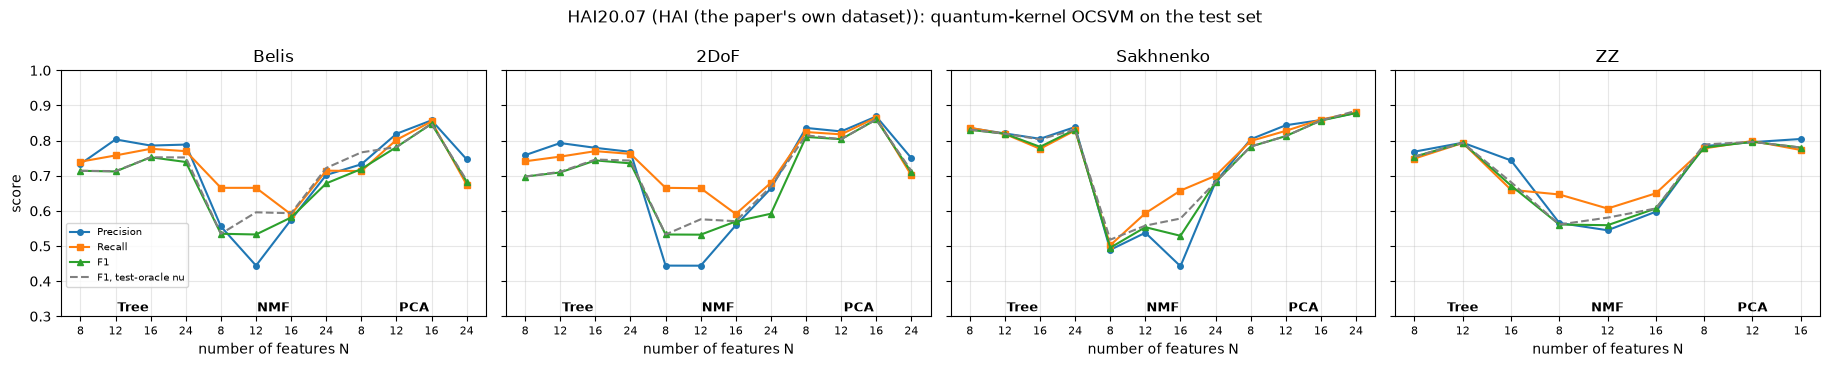

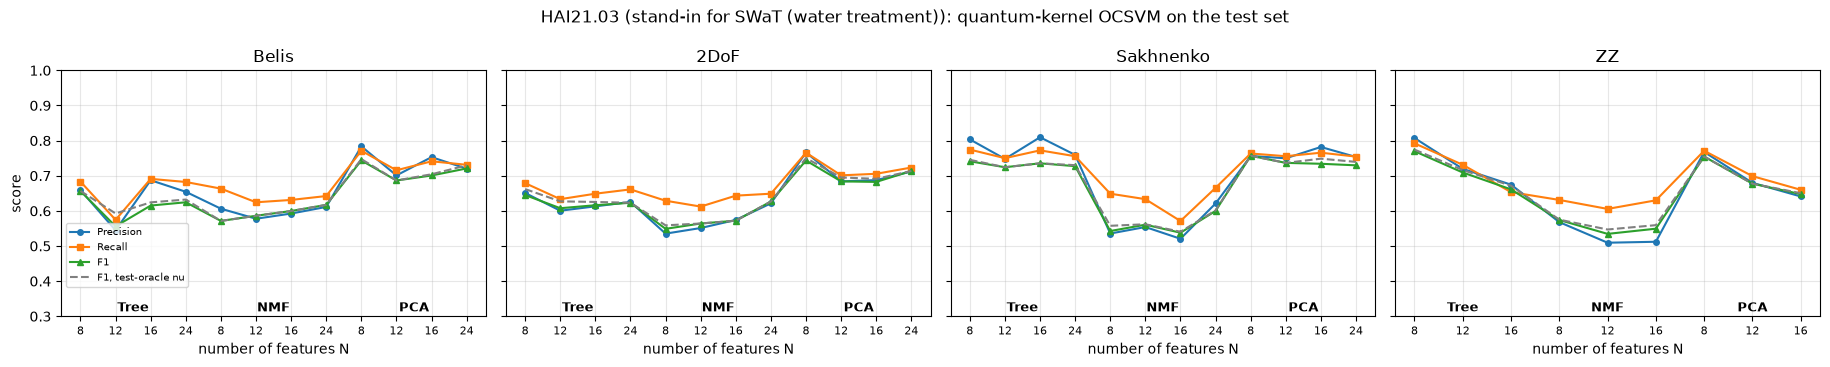

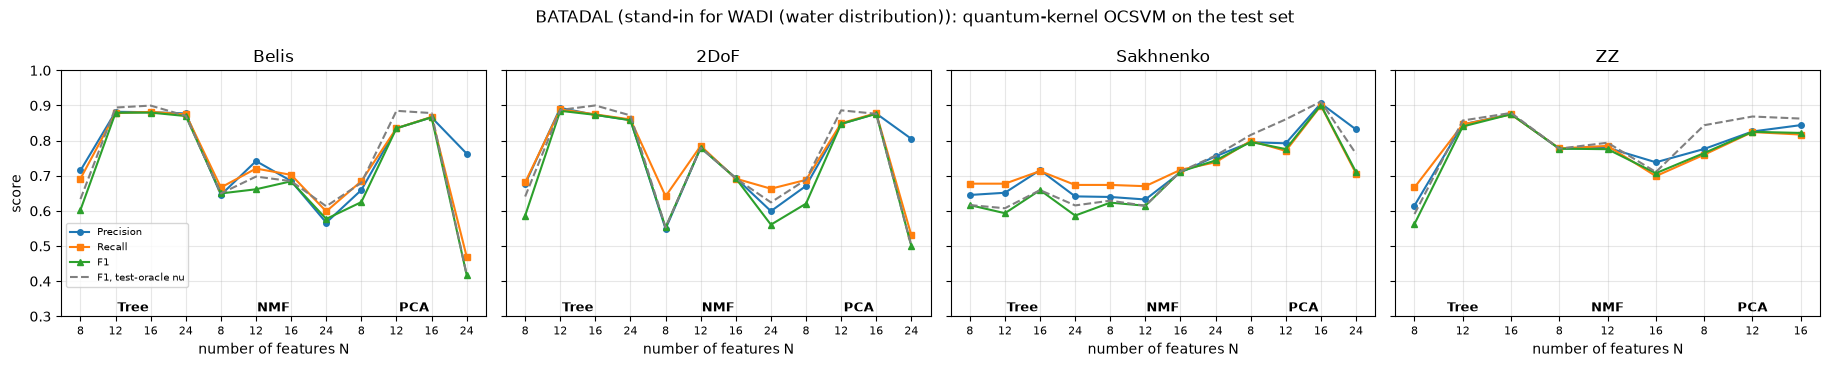

In [14]:
def lookup(name, red, N, model, col):
    s = G[(G.dataset == name) & (G.red == red) & (G.N == N) & (G.model == model)]
    return float(s[col].iloc[0]) if len(s) else np.nan

def fig_dataset(name):
    fig, axes = plt.subplots(1, len(FEATURE_MAPS), figsize=(4.6 * len(FEATURE_MAPS), 3.7), sharey=True)
    for ax, fm in zip(axes, FEATURE_MAPS):
        order = [(red, N) for red in REDUCTIONS for N in N_LIST if not (fm == "ZZ" and N > ZZ_MAX_N)]
        x = np.arange(len(order))
        for lab, col, st in (("Precision", "prec", "o-"), ("Recall", "rec", "s-"), ("F1", "f1", "^-")):
            ax.plot(x, [lookup(name, r, n, fm, col) for r, n in order], st, label=lab, ms=4)
        ax.plot(x, [lookup(name, r, n, fm, "f1_o") for r, n in order], "--", color="grey", label="F1, test-oracle nu")
        ax.set_xticks(x); ax.set_xticklabels([str(n) for _, n in order], fontsize=8)
        for i, red in enumerate(REDUCTIONS):
            k = [j for j, (r, _) in enumerate(order) if r == red]
            if k: ax.text(np.mean(k), 0.02, red, transform=ax.get_xaxis_transform(), ha="center", fontsize=9, weight="bold")
        ax.set_title(fm); ax.set_ylim(0.3, 1.0); ax.grid(alpha=.3); ax.set_xlabel("number of features N")
    axes[0].set_ylabel("score"); axes[0].legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 0.1))
    fig.suptitle(f"{name} ({SPEC[name]['role']}): quantum-kernel OCSVM on the test set"); plt.tight_layout(); plt.show()
for name in DATASETS: fig_dataset(name)

## 8. Classical kernels and the headline comparison (Fig. 10, Table VI)

The three classical kernels on exactly the same reduced inputs, then the best configuration per dataset for quantum and for classical kernels, chosen in two ways: by validation F1 (honest) and by test F1 (the paper's practice of reporting the best of the sweep).

In [15]:
Q, C = G[G.kind == "quantum"], G[G.kind == "classical"]
# Fig. 10 analogue: best configuration of each classical kernel per dataset
rows = []
for name in DATASETS:
    for k in CLASSICAL:
        s = C[(C.dataset == name) & (C.model == k)]
        b = s.loc[s.val_f1.idxmax()]; o = s.loc[s.f1_o.idxmax()]
        rows.append(dict(dataset=name, kernel=k, val_sel_config=f"{b.red}/{b.N}", val_sel_prec=b.prec, val_sel_rec=b.rec, val_sel_F1=b.f1,
                         oracle_config=f"{o.red}/{o.N}", oracle_prec=o.prec_o, oracle_rec=o.rec_o, oracle_F1=o.f1_o))
display(pd.DataFrame(rows).round(3))

# Table VI analogue: best quantum and best classical configuration per dataset
def best(name, kind, by):
    s = G[(G.dataset == name) & (G.kind == kind)]
    return s.loc[s.val_f1.idxmax()] if by == "val" else s.loc[s.f1_o.idxmax()]
rows = []
for name in DATASETS:
    for kind in ("quantum", "classical"):
        b, o = best(name, kind, "val"), best(name, kind, "oracle")
        rows.append(dict(dataset=name, kind=kind, val_selected=f"{b.model}/{b.red}/{b.N}", prec=b.prec, rec=b.rec, F1=b.f1,
                         test_oracle=f"{o.model}/{o.red}/{o.N}", prec_o=o.prec_o, rec_o=o.rec_o, F1_o=o.f1_o))
BESTTAB = pd.DataFrame(rows); display(BESTTAB.round(3))

# averages (the paper's "13.3 % better than classical counterparts across each preprocessed dataset and kernel")
def mean_f1(df, col): return df[col].mean()
rows = []
for name in DATASETS:
    q, c = Q[Q.dataset == name], C[C.dataset == name]
    for lab, col in (("validation-selected", "f1"), ("test-oracle nu", "f1_o")):
        rows.append(dict(dataset=name, selection=lab, mean_F1_quantum=mean_f1(q, col), mean_F1_classical=mean_f1(c, col),
                         difference=mean_f1(q, col) - mean_f1(c, col), relative_pct=100 * (mean_f1(q, col) - mean_f1(c, col)) / mean_f1(c, col)))
AVGTAB = pd.DataFrame(rows); display(AVGTAB.round(3))
print("average relative improvement of the quantum kernels over the classical ones (paper: 13.3 %):")
print(AVGTAB.groupby("selection").relative_pct.mean().round(1).to_dict())

,dataset,kernel,val_sel_config,val_sel_prec,val_sel_rec,val_sel_F1,oracle_config,oracle_prec,oracle_rec,oracle_F1
0,HAI20.07,poly,PCA/12,0.459,0.557,0.496,Tree/8,0.859,0.854,0.847
1,HAI20.07,rbf,PCA/12,0.814,0.817,0.810,PCA/16,0.850,0.851,0.850
2,HAI20.07,linear,Tree/8,0.802,0.752,0.703,Tree/12,0.853,0.836,0.822
3,HAI21.03,poly,NMF/8,0.572,0.640,0.572,NMF/12,0.611,0.601,0.606
4,HAI21.03,rbf,Tree/12,0.697,0.710,0.699,Tree/8,0.798,0.792,0.774
5,HAI21.03,linear,PCA/8,0.535,0.609,0.552,Tree/16,0.648,0.643,0.645
6,BATADAL,poly,NMF/12,0.560,0.566,0.563,PCA/24,0.815,0.814,0.803
7,BATADAL,rbf,Tree/8,0.617,0.667,0.573,PCA/16,0.903,0.896,0.898
8,BATADAL,linear,Tree/24,0.478,0.530,0.499,PCA/16,0.858,0.846,0.849


,dataset,kind,val_selected,prec,rec,F1,test_oracle,prec_o,rec_o,F1_o
0,HAI20.07,quantum,Sakhnenko/PCA/24,0.879,0.880,0.878,Sakhnenko/PCA/24,0.885,0.886,0.885
1,HAI20.07,classical,linear/Tree/8,0.802,0.752,0.703,rbf/PCA/16,0.850,0.851,0.850
2,HAI21.03,quantum,2DoF/NMF/12,0.551,0.612,0.564,ZZ/Tree/8,0.789,0.789,0.774
3,HAI21.03,classical,rbf/Tree/12,0.697,0.710,0.699,rbf/Tree/8,0.798,0.792,0.774
4,BATADAL,quantum,Sakhnenko/Tree/16,0.716,0.713,0.659,Sakhnenko/PCA/16,0.912,0.910,0.911
5,BATADAL,classical,rbf/Tree/8,0.617,0.667,0.573,rbf/PCA/16,0.903,0.896,0.898


,dataset,selection,mean_F1_quantum,mean_F1_classical,difference,relative_pct
0,HAI20.07,validation-selected,0.705,0.669,0.037,5.487
1,HAI20.07,test-oracle nu,0.716,0.699,0.016,2.344
2,HAI21.03,validation-selected,0.651,0.593,0.059,9.885
3,HAI21.03,test-oracle nu,0.657,0.614,0.043,6.997
4,BATADAL,validation-selected,0.721,0.641,0.081,12.627
5,BATADAL,test-oracle nu,0.743,0.688,0.055,8.040


average relative improvement of the quantum kernels over the classical ones (paper: 13.3 %):
{'test-oracle nu': 5.8, 'validation-selected': 9.3}


In [16]:
# Which pre-processing, which feature map, which feature count? (mean weighted F1, validation-selected | test-oracle in brackets)
def table_by(df, key):
    g = df.groupby(["dataset", key]).agg(f1=("f1", "mean"), f1_o=("f1_o", "mean")).round(3)
    return g.f1.astype(str).str.cat(g.f1_o.astype(str), sep=" | ").unstack(key)
print("QUANTUM, by reduction method:"); display(table_by(Q, "red")[list(REDUCTIONS)])
print("CLASSICAL, by reduction method:"); display(table_by(C, "red")[list(REDUCTIONS)])
print("QUANTUM, by feature map (all reductions and feature counts):"); display(table_by(Q, "model")[list(FEATURE_MAPS)])
print("QUANTUM, tree-selected features only, by number of features:"); display(table_by(Q[Q.red == "Tree"], "N"))

QUANTUM, by reduction method:


red,Tree,NMF,PCA
dataset,,,
BATADAL,0.745 | 0.762,0.674 | 0.686,0.746 | 0.782
HAI20.07,0.753 | 0.756,0.569 | 0.592,0.794 | 0.799
HAI21.03,0.667 | 0.676,0.572 | 0.576,0.714 | 0.719


CLASSICAL, by reduction method:


red,Tree,NMF,PCA
dataset,,,
BATADAL,0.641 | 0.697,0.618 | 0.671,0.663 | 0.697
HAI20.07,0.749 | 0.773,0.597 | 0.644,0.66 | 0.681
HAI21.03,0.627 | 0.643,0.56 | 0.588,0.591 | 0.61


QUANTUM, by feature map (all reductions and feature counts):


model,Belis,2DoF,Sakhnenko,ZZ
dataset,,,,
BATADAL,0.712 | 0.734,0.719 | 0.742,0.694 | 0.713,0.772 | 0.798
HAI20.07,0.69 | 0.705,0.691 | 0.703,0.738 | 0.747,0.7 | 0.705
HAI21.03,0.64 | 0.646,0.636 | 0.642,0.677 | 0.681,0.653 | 0.658


QUANTUM, tree-selected features only, by number of features:


N,8,12,16,24
dataset,,,,
BATADAL,0.592 | 0.62,0.799 | 0.812,0.822 | 0.834,0.771 | 0.786
HAI20.07,0.749 | 0.749,0.759 | 0.759,0.738 | 0.746,0.769 | 0.776
HAI21.03,0.703 | 0.71,0.649 | 0.665,0.657 | 0.664,0.658 | 0.662


## 9. Headline configurations over several seeds

The grid uses one split, as the paper does. For the best quantum and the best classical configuration of each dataset (chosen on **validation** F1) the pipeline is repeated with `N_SEEDS` different random training and test draws
(PCA / NMF refitted each time, `bw` / `gmult` re-used, `nu` re-selected on a fresh validation draw). Mean +- standard deviation.

HAI20.07 quantum 213 s


HAI20.07 classical 215 s


HAI21.03 quantum 223 s


HAI21.03 classical 226 s


BATADAL quantum 236 s


BATADAL classical 238 s


,dataset,kind,config,seeds,accuracy,precision,recall,F1,attack_F1,AUC,F1_test_oracle,seconds_per_run
0,HAI20.07,quantum,Sakhnenko/PCA/24,5,0.891 +- 0.008,0.894 +- 0.011,0.891 +- 0.008,0.888 +- 0.008,0.821 +- 0.010,0.873 +- 0.028,0.890 +- 0.006,43
1,HAI20.07,classical,linear/Tree/8,5,0.744 +- 0.044,0.771 +- 0.058,0.744 +- 0.044,0.705 +- 0.066,0.460 +- 0.170,0.509 +- 0.204,0.745 +- 0.037,1
2,HAI21.03,quantum,2DoF/NMF/12,5,0.626 +- 0.023,0.511 +- 0.050,0.626 +- 0.023,0.550 +- 0.021,0.132 +- 0.113,0.480 +- 0.034,0.561 +- 0.012,1
3,HAI21.03,classical,rbf/Tree/12,5,0.711 +- 0.026,0.700 +- 0.030,0.711 +- 0.026,0.698 +- 0.024,0.501 +- 0.037,0.731 +- 0.024,0.719 +- 0.011,1
4,BATADAL,quantum,Sakhnenko/Tree/16,5,0.696 +- 0.012,0.687 +- 0.028,0.696 +- 0.012,0.635 +- 0.015,0.293 +- 0.033,0.594 +- 0.022,0.639 +- 0.011,2
5,BATADAL,classical,rbf/Tree/8,5,0.662 +- 0.008,0.605 +- 0.019,0.662 +- 0.008,0.567 +- 0.008,0.121 +- 0.029,0.586 +- 0.026,0.621 +- 0.024,0


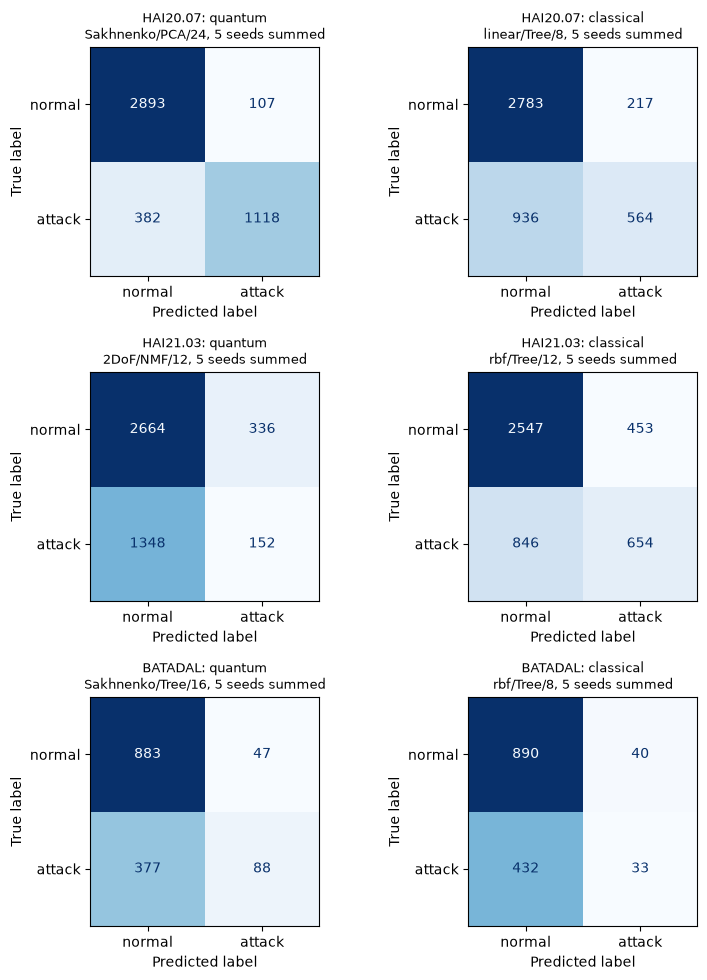

In [17]:
SEEDRES = {}
t0 = time.time(); rows = []
for name in DATASETS:
    for kind in ("quantum", "classical"):
        b = best(name, kind, "val"); lst = []
        for s in range(N_SEEDS):
            lst.append(run_cfg(name, b.red, int(b.N), b.model, seed=s, hp=HP[(name, b.red, int(b.N), b.model)]))
        SEEDRES[(name, kind)] = lst
        f = lambda k: f"{np.mean([r[k] for r in lst]):.3f} +- {np.std([r[k] for r in lst]):.3f}"
        rows.append(dict(dataset=name, kind=kind, config=f"{b.model}/{b.red}/{b.N}", seeds=N_SEEDS, accuracy=f("acc"), precision=f("prec"), recall=f("rec"),
                         F1=f("f1"), attack_F1=f("att_f1"), AUC=f("auc"), F1_test_oracle=f("f1_o"), seconds_per_run=f"{np.mean([r['seconds'] for r in lst]):.0f}"))
        print(name, kind, f"{time.time()-t0:.0f} s")
SEEDTAB = pd.DataFrame(rows); display(SEEDTAB)

fig, axes = plt.subplots(len(DATASETS), 2, figsize=(8, 3.3 * len(DATASETS)))
for i, name in enumerate(DATASETS):
    for j, kind in enumerate(("quantum", "classical")):
        cm = sum(r["cm"] for r in SEEDRES[(name, kind)]); b = best(name, kind, "val")
        ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=axes[i, j], colorbar=False, cmap="Blues", values_format="d")
        axes[i, j].set_title(f"{name}: {kind}\n{b.model}/{b.red}/{b.N}, {N_SEEDS} seeds summed", fontsize=9)
plt.tight_layout(); plt.show()

## 10. Kernel-target alignment (the paper's "quantum advantage" indicator, Table V)

`KTA(K, y) = <K, y y^T>_F / (|K|_F |y y^T|_F)` with class-rescaled labels (PennyLane's `target_alignment`, checked in Section 5b). It was computed for each
kernel and reduction on a labelled draw of 400 validation windows (balanced as in the validation block), with the hyper-parameters that the grid selected. A kernel that
puts same-class windows close together and different-class windows far apart aligns better with the labels. The paper reads a clearly higher quantum alignment as evidence of a quantum advantage;
that reading is discussed in Sections 10b and 14.

In [18]:
Kt = G[G.kta.notna()].copy()
if len(Kt):
    for name in DATASETS:
        t = Kt[Kt.dataset == name].pivot_table(index="red", columns="model", values="kta").reindex(list(REDUCTIONS))
        print(f"{name} (N = {KTA_N}):"); display(t[[c for c in ("Belis", "2DoF", "Sakhnenko", "rbf", "poly", "linear") if c in t.columns]].round(4))
    qa, ca = Kt[Kt.kind == "quantum"].kta.mean(), Kt[Kt.kind == "classical"].kta.mean()
    print(f"mean KTA: quantum {qa:.4f} | classical {ca:.4f} | difference {qa - ca:+.4f} (paper +0.048) | relative change {100 * (qa - ca) / ca:+.1f} % (paper +91.0 %)")
    KTA_RES = dict(q=qa, c=ca)
else:
    print("no KTA values recorded"); KTA_RES = None

HAI20.07 (N = 16):


model,Belis,2DoF,Sakhnenko,rbf,poly,linear
red,,,,,,
Tree,0.0031,0.0005,0.0002,0.0194,0.0488,0.0891
NMF,0.0111,0.0003,0.0002,0.0047,0.0692,0.0517
PCA,0.0151,0.0005,0.0008,0.0280,0.0480,0.1031


HAI21.03 (N = 16):


model,Belis,2DoF,Sakhnenko,rbf,poly,linear
red,,,,,,
Tree,0.0603,0.0816,0.1633,0.1222,0.0590,0.0744
NMF,0.0773,0.0060,0.0543,0.1121,0.1960,0.1003
PCA,0.0086,0.0008,0.0005,0.0818,0.0727,0.0843


BATADAL (N = 16):


model,Belis,2DoF,Sakhnenko,rbf,poly,linear
red,,,,,,
Tree,0.0136,0.0135,0.1207,0.1249,0.1674,0.2424
NMF,0.0297,0.0311,0.0026,0.0609,0.0342,0.1062
PCA,0.0110,0.0025,0.0041,0.0959,0.0806,0.2697


mean KTA: quantum 0.0264 | classical 0.0943 | difference -0.0679 (paper +0.048) | relative change -72.0 % (paper +91.0 %)


### 10b. Kernel-target alignment depends on the kernel parameter

The numbers above use the bandwidth that was best for *classification* (validation F1), which is often small, i.e. a nearly flat kernel with tiny alignment. Alignment is a property of the kernel parameter as much as of the circuit:
below it is computed for every `bw` of the grid (quantum) and every `gmult` of the grid (RBF, polynomial; the linear kernel has no parameter) on the same validation draw, and the **best** parameter of each kernel is compared. This is the fairer reading of "quantum versus classical alignment".

kernel,Belis,2DoF,Sakhnenko,rbf,poly,linear
dataset,,,,,,
BATADAL,0.0917,0.0547,0.1278,0.1249,0.1710,0.2424
HAI20.07,0.1083,0.0832,0.0823,0.1028,0.0568,0.0891
HAI21.03,0.1720,0.1908,0.2563,0.1923,0.0592,0.0744


tree features, N = 16: mean of the best-parameter KTA: quantum 0.1297 | classical 0.1236 | difference +0.0060 (paper +0.048)


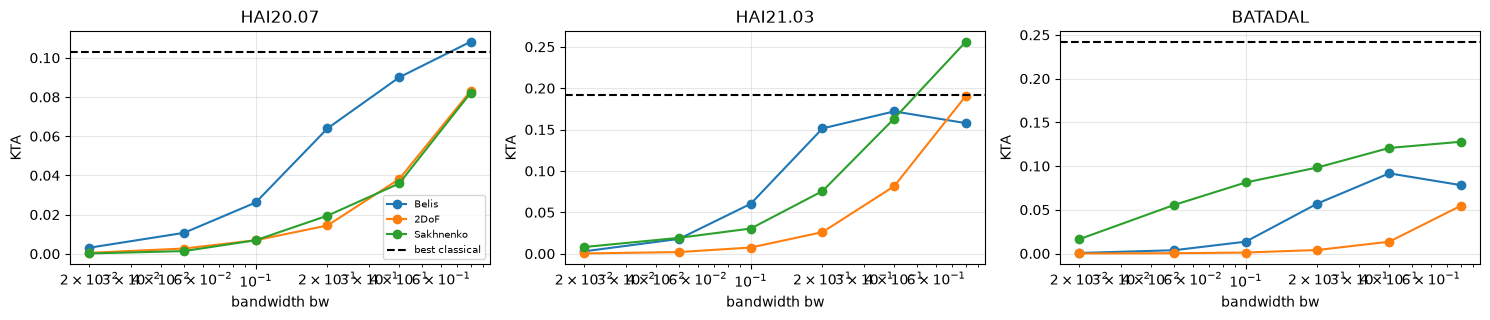

In [19]:
rows = []
for name in DATASETS:
    S = get_split(name, 0); F = get_features(name, "Tree", KTA_N, 0)
    sel = np.random.default_rng(SEED + 3).permutation(len(F["va"]))[:KTA_MAX]; X = F["va"][sel]; y = np.where(S["yva"][sel] == 1, 1, -1); g0 = 1.0 / (KTA_N * F["tr"].var())
    for fm in ("Belis", "2DoF", "Sakhnenko"):
        for bw in BW_GRID: rows.append(dict(dataset=name, kernel=fm, kind="quantum", parameter=f"bw={bw}", kta=kta(qkernel(fm, angles(X, bw)), y)))
    for k in ("rbf", "poly"):
        for gm in GAMMA_MULTS: rows.append(dict(dataset=name, kernel=k, kind="classical", parameter=f"gmult={gm}", kta=kta(gram(k, X, X, gm * g0), y)))
    rows.append(dict(dataset=name, kernel="linear", kind="classical", parameter="-", kta=kta(gram("linear", X, X), y)))
KB = pd.DataFrame(rows)
best_kta = KB.loc[KB.groupby(["dataset", "kernel"]).kta.idxmax()]
display(best_kta.pivot(index="dataset", columns="kernel", values="kta")[["Belis", "2DoF", "Sakhnenko", "rbf", "poly", "linear"]].round(4))
qb, cb = best_kta[best_kta.kind == "quantum"].kta.mean(), best_kta[best_kta.kind == "classical"].kta.mean()
KTA_BEST = dict(q=qb, c=cb)
print(f"tree features, N = {KTA_N}: mean of the best-parameter KTA: quantum {qb:.4f} | classical {cb:.4f} | difference {qb - cb:+.4f} (paper +0.048)")
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 3.3))
for a, name in zip(np.atleast_1d(ax), DATASETS):
    for fm in ("Belis", "2DoF", "Sakhnenko"):
        s = KB[(KB.dataset == name) & (KB.kernel == fm)]; a.plot(BW_GRID, s.kta.values, "o-", label=fm)
    a.set_xscale("log"); a.set_xlabel("bandwidth bw"); a.set_ylabel("KTA"); a.set_title(name); a.grid(alpha=.3)
    a.axhline(best_kta[(best_kta.dataset == name) & (best_kta.kind == "classical")].kta.max(), color="k", ls="--", label="best classical")
np.atleast_1d(ax)[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 11. Noise study (Tables II to IV)

The paper simulates the fidelity circuits of the two best maps (Belis, 2DoF) with Qiskit Aer density-matrix simulations and noise snapshots of IBM Kyiv, Sherbrooke and Torino. Here the
snapshots shipped with `qiskit-ibm-runtime` (`FakeKyiv`, `FakeSherbrooke`, `FakeTorino`) are used, so the error rates differ from the paper's Table II (different dates; the table below shows ours).

**Procedure.** For one configuration (tree features, `bw` from the grid) the compute-uncompute circuit `U(y)^dagger U(x)` is transpiled once to the device (basis gates, routing), a parameter set is bound for
every pair of samples, and the probability of the all-zero outcome is estimated from `NOISE_SHOTS` shots with the device noise (gate errors, relaxation, readout errors). The kernel
dissimilarity is `1 - KA(K_ideal, K_noisy)` as in the paper; the column "shot floor" shows the same quantity for an *ideal* circuit sampled with the same number of shots, i.e. the part of the dissimilarity that is plain sampling noise.
Then the OCSVM (fixed `nu = NOISE_NU`) is trained on the ideal and on the noisy kernel of the same small sample and the relative change of the weighted metrics is reported (Table III).
Every kernel entry is a separate circuit, so the samples are small (tens of windows): the classification changes are noisy and should be read as indicative only.

In [20]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import fake_provider as fp

BACKENDS = {b: getattr(fp, b)() for b in NOISE_BACKENDS}
def summarize_backend(be):
    t = be.target; med = lambda v: float(np.median(v)) if len(v) else np.nan
    err = lambda op: med([p.error for p in t[op].values() if p is not None and p.error is not None]) if op in t.operation_names else np.nan
    two = "ecr" if "ecr" in t.operation_names else "cz"
    t1 = med([qp.t1 for qp in t.qubit_properties if qp is not None and qp.t1]) * 1e6; t2 = med([qp.t2 for qp in t.qubit_properties if qp is not None and qp.t2]) * 1e6
    return dict(qubits=be.num_qubits, two_qubit_gate=two, median_2q_error=err(two), median_sx_error=err("sx"), median_readout_error=err("measure"), T1_us=t1, T2_us=t2)
PAPER_T2 = {"FakeTorino": dict(median_2q_error=2.936e-3, median_sx_error=3.149e-4, median_readout_error=2.6e-2, T1_us=177.93, T2_us=137.79),
            "FakeSherbrooke": dict(median_2q_error=7.726e-3, median_sx_error=2.582e-4, median_readout_error=1.39e-2, T1_us=262.43, T2_us=164.33),
            "FakeKyiv": dict(median_2q_error=1.208e-2, median_sx_error=2.779e-4, median_readout_error=8.2e-3, T1_us=265.84, T2_us=101.59)}
rows = []
for b, be in BACKENDS.items():
    s = summarize_backend(be); rows.append(dict(backend=b, source="this notebook", **s))
    rows.append(dict(backend=b, source="paper Table II", qubits=np.nan, two_qubit_gate="", **PAPER_T2[b]))
display(pd.DataFrame(rows).set_index(["backend", "source"]))

qubits two_qubit_gate  median_2q_error  median_sx_error  median_readout_error       T1_us       T2_us
backend        source                                                                                                               
FakeKyiv       this notebook    127.0            ecr         0.011718         0.000252              0.012695  287.100085  118.103860
               paper Table II     NaN                        0.012080         0.000278              0.008200  265.840000  101.590000
FakeSherbrooke this notebook    127.0            ecr         0.007788         0.000236              0.019775  278.419721  170.012742
               paper Table II     NaN                        0.007726         0.000258              0.013900  262.430000  164.330000
FakeTorino     this notebook    133.0             cz         0.004190         0.000271              0.022949  184.987426  140.938949
               paper Table II     NaN                        0.002936         0.000315              0.026000  177.930000  137.790000

In [21]:
def pair_circuit(fm, N):
    f = CIRCUITS[fm]; qa = f(N); nq = qa.num_qubits
    xs, ys = ParameterVector("x", N), ParameterVector("y", N)
    a, b = qa.assign_parameters(list(xs)), qa.assign_parameters(list(ys))
    qc = QuantumCircuit(nq); qc.compose(a, inplace=True); qc.compose(b.inverse(), inplace=True); qc.measure_all()
    return qc, list(xs), list(ys)

_tp_cache, _sim_cache = {}, {}
def transpiled(fm, N, bname):
    k = (fm, N, bname)
    if k not in _tp_cache:
        qc, xs, ys = pair_circuit(fm, N)
        _tp_cache[k] = (transpile(qc, BACKENDS[bname], optimization_level=1, seed_transpiler=SEED), xs, ys)      # CHOICE: optimisation level 1
    if bname not in _sim_cache:
        _sim_cache[bname] = AerSimulator(method="density_matrix", noise_model=NoiseModel.from_backend(BACKENDS[bname]),
                                         max_parallel_experiments=NOISE_THREADS)
    return _tp_cache[k], _sim_cache[bname]

def noisy_zero_prob(fm, N, bname, X, Y, batch=200):
    """P(all zeros) of U(y)^dagger U(x) under the device noise for every row pair (X[i], Y[i])."""
    (tq, xs, ys), sim = transpiled(fm, N, bname); nq = QUBITS(fm, N); zero = "0" * nq; out = []
    for s in range(0, len(X), batch):
        cs = [tq.assign_parameters(dict(zip(xs + ys, np.r_[x, y]))) for x, y in zip(X[s:s + batch], Y[s:s + batch])]
        res = sim.run(cs, shots=NOISE_SHOTS, seed_simulator=SEED).result()
        out += [res.get_counts(i).get(zero, 0) / NOISE_SHOTS for i in range(len(cs))]
    return np.array(out)

KA = lambda K1, K2: float((K1 * K2).sum() / np.sqrt((K1 * K1).sum() * (K2 * K2).sum()))       # paper Eq. 1 (Frobenius cosine)
def ocsvm_eval(Ktr, Kte, y, nu=NOISE_NU):
    oc = OneClassSVM(kernel="precomputed", nu=nu).fit(np.exp(Ktr)); d = oc.decision_function(np.exp(Kte)); return metrics(y, (d < 0).astype(int), -d)

def noise_experiment(name, fm, N, bname):
    t0 = time.time(); S, F = get_split(name, 0), get_features(name, "Tree", N, 0); bw = HP[(name, "Tree", N, fm)]["bw"]
    rr = np.random.default_rng(SEED + 11)
    te = np.r_[rr.choice(np.flatnonzero(S["yte"] == 0), NOISE_NTE_NORM, replace=False), rr.choice(np.flatnonzero(S["yte"] == 1), NOISE_NTE_ANOM, replace=False)]
    yE = S["yte"][te]; A = angles(F["tr"][:NOISE_NTR], bw); E = angles(F["te"][te], bw)
    Ki_tr, Ki_te = qkernel(fm, A), qkernel(fm, E, A)
    iu = np.triu_indices(NOISE_NTR); p = noisy_zero_prob(fm, N, bname, A[iu[0]], A[iu[1]])
    Kn_tr = np.zeros((NOISE_NTR, NOISE_NTR)); Kn_tr[iu] = p; Kn_tr = Kn_tr + Kn_tr.T - np.diag(np.diag(Kn_tr))
    ei, aj = np.meshgrid(np.arange(len(E)), np.arange(NOISE_NTR), indexing="ij")
    Kn_te = noisy_zero_prob(fm, N, bname, E[ei.ravel()], A[aj.ravel()]).reshape(len(E), NOISE_NTR)
    rs = np.random.default_rng(SEED + 12)                                    # shot-noise-only baseline from the exact kernel
    Ks_tr = rs.binomial(NOISE_SHOTS, np.clip(Ki_tr, 0, 1)) / NOISE_SHOTS; Ks_tr = np.triu(Ks_tr) + np.triu(Ks_tr, 1).T
    mi, mn = ocsvm_eval(Ki_tr, Ki_te, yE), ocsvm_eval(Kn_tr, Kn_te, yE)
    row = dict(dataset=name, map=fm, N=N, backend=bname, DErr_train=1 - KA(Ki_tr, Kn_tr), DErr_test=1 - KA(Ki_te, Kn_te), shot_floor=1 - KA(Ki_tr, Ks_tr),
               mean_abs_kernel_err=float(np.abs(Ki_te - Kn_te).mean()), n_circuits=len(p) + Kn_te.size, seconds=time.time() - t0)
    for k, lab in (("prec", "prec"), ("rec", "rec"), ("f1", "f1")):
        row[f"ideal_{lab}"] = mi[k]; row[f"noisy_{lab}"] = mn[k]
        row[f"drop_{lab}_pct"] = 100 * (mi[k] - mn[k]) / mi[k] if mi[k] >= 0.5 else np.nan      # percent change only where the ideal metric is meaningful (>= 0.5)
        row[f"drop_{lab}_pts"] = 100 * (mi[k] - mn[k])
    return row

NOISE = []
t0 = time.time()
for name in NOISE_DATASETS:
    for fm in ("Belis", "2DoF"):
        for N in NOISE_N:
            for b in NOISE_BACKENDS:
                NOISE.append(noise_experiment(name, fm, N, b))
                print(f"{name:9s} {fm:5s} N={N:2d} {b:15s} DErr(train)={NOISE[-1]['DErr_train']:.2e}  shot floor={NOISE[-1]['shot_floor']:.2e}  "
                      f"{NOISE[-1]['n_circuits']} circuits in {NOISE[-1]['seconds']:.0f} s  (total {(time.time()-t0)/60:.1f} min)")
NZ = pd.DataFrame(NOISE)

HAI20.07  Belis N= 8 FakeKyiv        DErr(train)=1.49e-04  shot floor=1.49e-05  810 circuits in 58 s  (total 1.0 min)


HAI20.07  Belis N= 8 FakeSherbrooke  DErr(train)=1.44e-04  shot floor=1.49e-05  810 circuits in 54 s  (total 1.9 min)


HAI20.07  Belis N= 8 FakeTorino      DErr(train)=1.09e-04  shot floor=1.49e-05  810 circuits in 58 s  (total 2.8 min)


HAI20.07  Belis N=12 FakeKyiv        DErr(train)=3.39e-05  shot floor=1.37e-06  810 circuits in 76 s  (total 4.1 min)


HAI20.07  Belis N=12 FakeSherbrooke  DErr(train)=4.11e-05  shot floor=1.37e-06  810 circuits in 94 s  (total 5.7 min)


...

BATADAL   2DoF  N= 8 FakeSherbrooke  DErr(train)=2.43e-05  shot floor=1.62e-05  810 circuits in 32 s  (total 29.1 min)


BATADAL   2DoF  N= 8 FakeTorino      DErr(train)=2.97e-04  shot floor=1.62e-05  810 circuits in 45 s  (total 29.8 min)


BATADAL   2DoF  N=12 FakeKyiv        DErr(train)=6.66e-05  shot floor=2.34e-05  810 circuits in 35 s  (total 30.4 min)


BATADAL   2DoF  N=12 FakeSherbrooke  DErr(train)=6.30e-05  shot floor=2.34e-05  810 circuits in 35 s  (total 31.0 min)


BATADAL   2DoF  N=12 FakeTorino      DErr(train)=3.24e-04  shot floor=2.34e-05  810 circuits in 38 s  (total 31.6 min)


In [22]:
print("Table IV analogue: kernel dissimilarity 1 - KA(K_ideal, K_noisy) on the training kernel (and the sampling-only floor):")
t4 = NZ.pivot_table(index=["dataset", "N"], columns=["backend", "map"], values="DErr_train"); display(t4.map(lambda v: f"{v:.2e}"))
print("shot-noise floor (ideal circuit, same shots):"); display(NZ.pivot_table(index=["dataset", "N"], columns=["map"], values="shot_floor", aggfunc="mean").map(lambda v: f"{v:.2e}"))
print("Table III analogue: percent decrease of the weighted metrics, noisy vs ideal kernel (mean over backends):")
t3 = NZ.groupby(["dataset", "map", "N"])[["drop_prec_pct", "drop_rec_pct", "drop_f1_pct", "drop_f1_pts"]].mean().round(2); display(t3)
print("by backend (mean over everything):"); display(NZ.groupby("backend")[["DErr_train", "DErr_test", "drop_f1_pct", "drop_f1_pts"]].mean())
print("by feature map:"); display(NZ.groupby("map")[["DErr_train", "DErr_test", "drop_f1_pct", "drop_f1_pts"]].mean())
NOISE_SUM = dict(max_derr=max(NZ.DErr_train.max(), NZ.DErr_test.max()), mean_drop=float(np.nanmean(np.abs(NZ[["drop_prec_pct", "drop_rec_pct", "drop_f1_pct"]].to_numpy()))), mean_drop_pts=float(np.nanmean(np.abs(NZ[["drop_prec_pts", "drop_rec_pts", "drop_f1_pts"]].to_numpy()))),
                 worst_backend=NZ.groupby("backend").DErr_train.mean().idxmax(), belis_gt_2dof=float(NZ[NZ["map"] == "Belis"].DErr_train.mean() > NZ[NZ["map"] == "2DoF"].DErr_train.mean()) if NZ["map"].nunique() == 2 else np.nan)
print(NOISE_SUM)

Table IV analogue: kernel dissimilarity 1 - KA(K_ideal, K_noisy) on the training kernel (and the sampling-only floor):


backend      FakeKyiv           FakeSherbrooke           FakeTorino          
map              2DoF     Belis           2DoF     Belis       2DoF     Belis
dataset  N                                                                   
BATADAL  8   2.02e-05  1.19e-04       2.43e-05  1.20e-04   2.97e-04  8.89e-05
         12  6.66e-05  1.35e-03       6.30e-05  1.86e-03   3.24e-04  7.75e-04
HAI20.07 8   3.44e-06  1.49e-04       5.80e-06  1.44e-04   1.82e-05  1.09e-04
         12  1.08e-05  3.39e-05       1.24e-05  4.11e-05   2.54e-05  3.87e-05
HAI21.03 8   2.65e-05  3.30e-05       4.17e-05  3.46e-05   2.32e-04  3.81e-05
         12  1.08e-05  3.63e-05       1.17e-05  4.25e-05   2.67e-05  3.91e-05

shot-noise floor (ideal circuit, same shots):


map              2DoF     Belis
dataset  N                     
BATADAL  8   1.62e-05  1.88e-05
         12  2.34e-05  6.37e-05
HAI20.07 8   9.65e-07  1.49e-05
         12  1.83e-06  1.37e-06
HAI21.03 8   1.99e-05  4.95e-06
         12  1.88e-06  1.29e-06

Table III analogue: percent decrease of the weighted metrics, noisy vs ideal kernel (mean over backends):


...

by backend (mean over everything):


,DErr_train,DErr_test,drop_f1_pct,drop_f1_pts
backend,,,,
FakeKyiv,0.000155,0.000366,-3.039485,-1.995043
FakeSherbrooke,0.000200,0.000546,-2.342732,-1.723553
FakeTorino,0.000168,0.000287,-1.908126,-1.195231


by feature map:


,DErr_train,DErr_test,drop_f1_pct,drop_f1_pts
map,,,,
2DoF,0.000068,0.000173,-3.002113,-1.659088
Belis,0.000281,0.000627,-1.572117,-1.616797


{'max_derr': np.float64(0.0058757620829508195), 'mean_drop': 4.351000196454462, 'mean_drop_pts': 2.639665863636699, 'worst_backend': 'FakeSherbrooke', 'belis_gt_2dof': 1.0}


## 12. Ablations on choices the paper leaves open

1. **The literal `U(pi/2, phi, lambda)` encoding** (Section 5b): the kernel is blind to every second feature. Compared with the dense angle encoding on the same inputs.
2. **Natural anomaly rate.** The 2:1 test mix is artificial (HAI is 4 % anomalous, BATADAL 5 %). The best validation-selected quantum and classical configurations are scored on a random draw of evaluation windows at their natural rate,
   together with the accuracy of the trivial "always normal" classifier.

In [23]:
NA = max(n for n in N_LIST if n <= 16); rows = []
for name in DATASETS:
    for fm in ("2DoF", "U2literal"):
        r = run_cfg(name, "Tree", NA, fm, seed=0)
        rows.append(dict(dataset=name, map=fm, features=NA, qubits=NA // 2, val_F1=r["val_f1"], test_F1=r["f1"], test_acc=r["acc"], AUC=r["auc"], F1_test_oracle=r["f1_o"]))
display(pd.DataFrame(rows).round(3))

rows = []
for name in DATASETS:
    for kind in ("quantum", "classical"):
        b = best(name, kind, "val"); r = run_cfg(name, b.red, int(b.N), b.model, seed=0, hp=HP[(name, b.red, int(b.N), b.model)], tag="natural")
        yv = get_split(name, 0, "natural")["yte"]; tn, fp_, fn, tp = r["cm"].ravel()
        rows.append(dict(dataset=name, kind=kind, config=f"{b.model}/{b.red}/{b.N}", windows=len(yv), anomaly_rate=round(yv.mean(), 3), always_normal_acc=round(1 - yv.mean(), 3),
                         accuracy=r["acc"], weighted_F1=r["f1"], attack_precision=tp / max(tp + fp_, 1), attack_recall=tp / max(tp + fn, 1), attack_F1=r["att_f1"], AUC=r["auc"]))
NATTAB = pd.DataFrame(rows); display(NATTAB.round(3))

,dataset,map,features,qubits,val_F1,test_F1,test_acc,AUC,F1_test_oracle
0,HAI20.07,2DoF,16,8,0.694,0.744,0.770,0.600,0.746
1,HAI20.07,U2literal,16,8,0.694,0.744,0.770,0.597,0.745
2,HAI21.03,2DoF,16,8,0.820,0.616,0.649,0.560,0.625
3,HAI21.03,U2literal,16,8,0.806,0.614,0.647,0.564,0.625
4,BATADAL,2DoF,16,8,0.810,0.873,0.875,0.901,0.900
5,BATADAL,U2literal,16,8,0.796,0.874,0.875,0.888,0.904


,dataset,kind,config,windows,anomaly_rate,always_normal_acc,accuracy,weighted_F1,attack_precision,attack_recall,attack_F1,AUC
0,HAI20.07,quantum,Sakhnenko/PCA/24,4000,0.043,0.957,0.913,0.931,0.300,0.784,0.434,0.905
1,HAI20.07,classical,linear/Tree/8,4000,0.043,0.957,0.962,0.954,0.652,0.251,0.363,0.401
2,HAI21.03,quantum,2DoF/NMF/12,4000,0.028,0.972,0.820,0.877,0.025,0.144,0.042,0.548
3,HAI21.03,classical,rbf/Tree/12,4000,0.028,0.972,0.827,0.882,0.068,0.414,0.117,0.692
4,BATADAL,quantum,Sakhnenko/Tree/16,1659,0.071,0.929,0.895,0.893,0.241,0.231,0.236,0.592
5,BATADAL,classical,rbf/Tree/8,1659,0.071,0.929,0.904,0.891,0.169,0.094,0.121,0.589


## 13. Side by side with the paper

Verdict rule for every numeric claim: **reproduced** if our value is within 0.02 (2 accuracy points) of the paper's value; otherwise **not reached** (ours is lower) or **exceeded** (ours is higher) with the gap. Relational claims ("A beats B")
are judged on our means. Claims about SWaT and WADI are evaluated on the **stand-in datasets** (HAI 21.03, BATADAL) and are marked *(substitute data)*: a mismatch there does not refute the paper, a match is not a confirmation either.
Two numbers are given for the classification claims: with `nu` chosen on the validation block (honest) and with the best `nu` on the test set (the paper's described practice).

In [24]:
PAPER_VI = {"HAI20.07": ("Belis", 16, (.88, .87, .86), "HAI"), "HAI21.03": ("2DoF", 12, (.95, .95, .95), "SWaT (substitute data)"), "BATADAL": ("2DoF", 16, (.90, .88, .88), "WADI (substitute data)")}
def verdict(ours, paper, tol=0.02):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked here"
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.3f})" if gap > 0 else f"not reached ({gap:.3f})")
rel = lambda cond: "reproduced" if cond else "not reached"
rows = []
def add(claim, paper, ours, ours_o, ver, ver_o=None):
    rows.append(dict(claim=claim, paper=paper, notebook_validation_selected=ours, notebook_test_oracle=ours_o, verdict=ver, verdict_test_oracle=ver_o if ver_o is not None else ver))

# --- Table VI: best configuration per dataset, same configuration in this notebook (closest available feature count)
for name, (fm, N, pvals, label) in PAPER_VI.items():
    Nn = min(N_LIST, key=lambda n: abs(n - N))
    if fm == "ZZ" and Nn > ZZ_MAX_N: Nn = ZZ_MAX_N
    for lab, col, colo, pv in zip(("precision", "recall", "F1"), ("prec", "rec", "f1"), ("prec_o", "rec_o", "f1_o"), pvals):
        o, oo = lookup(name, "Tree", Nn, fm, col), lookup(name, "Tree", Nn, fm, colo)
        add(f"Table VI {label}: {fm}, {N} tree features (ours: {Nn} features) - {lab}", pv, round(o, 3), round(oo, 3), verdict(o, pv), verdict(oo, pv))
# --- best of the whole grid per dataset
for name, (fm, N, pvals, label) in PAPER_VI.items():
    bq, oq = best(name, "quantum", "val"), best(name, "quantum", "oracle")
    add(f"best quantum F1 anywhere in the grid, {label}", pvals[2], f"{bq.f1:.3f} ({bq.model}/{bq.red}/{bq.N})", f"{oq.f1_o:.3f} ({oq.model}/{oq.red}/{oq.N})", verdict(bq.f1, pvals[2]), verdict(oq.f1_o, pvals[2]))
# --- classical best
for name, pv, label in (("HAI21.03", .89, "SWaT (substitute data): RBF + tree, F1 .89"), ("HAI20.07", .78, "HAI: poly/linear + tree, F1 .78")):
    bc, oc = best(name, "classical", "val"), best(name, "classical", "oracle")
    add(f"best classical F1, {label}", pv, f"{bc.f1:.3f} ({bc.model}/{bc.red}/{bc.N})", f"{oc.f1_o:.3f} ({oc.model}/{oc.red}/{oc.N})", verdict(bc.f1, pv), verdict(oc.f1_o, pv))
cw = C[C.dataset == "BATADAL"]
add("mean classical F1 over all classical configurations, WADI (substitute data)", .722, round(cw.f1.mean(), 3), round(cw.f1_o.mean(), 3), verdict(cw.f1.mean(), .722), verdict(cw.f1_o.mean(), .722))
# --- quantum vs classical
a = AVGTAB.groupby("selection").relative_pct.mean()
add("average relative F1 gain of quantum over classical kernels (percent)", 13.3, round(a["validation-selected"], 1), round(a["test-oracle nu"], 1), verdict(a["validation-selected"], 13.3, 2.0), verdict(a["test-oracle nu"], 13.3, 2.0))
h = AVGTAB[AVGTAB.dataset == "HAI20.07"].set_index("selection")
add("HAI: quantum minus classical mean F1, relative percent", 11.8, round(h.loc["validation-selected", "relative_pct"], 1), round(h.loc["test-oracle nu", "relative_pct"], 1),
    verdict(h.loc["validation-selected", "relative_pct"], 11.8, 2.0), verdict(h.loc["test-oracle nu", "relative_pct"], 11.8, 2.0))
qwin = [bool(AVGTAB[(AVGTAB.dataset == n) & (AVGTAB.selection == "validation-selected")].difference.iloc[0] > 0) for n in DATASETS]
qwin_o = [bool(AVGTAB[(AVGTAB.dataset == n) & (AVGTAB.selection == "test-oracle nu")].difference.iloc[0] > 0) for n in DATASETS]
add("quantum kernels beat classical ones on every dataset (mean F1)", "yes, all three", f"{sum(qwin)} of {len(qwin)} datasets", f"{sum(qwin_o)} of {len(qwin_o)} datasets", rel(all(qwin)), rel(all(qwin_o)))
# --- pre-processing and feature maps
qr = Q.groupby("red").f1.mean(); qro = Q.groupby("red").f1_o.mean(); cr = C.groupby("red").f1.mean()
add("tree selection is the best reduction for quantum kernels", "yes", f"best = {qr.idxmax()} ({qr.round(3).to_dict()})", f"best = {qro.idxmax()}", rel(qr.idxmax() == "Tree"), rel(qro.idxmax() == "Tree"))
add("NMF is the worst reduction (quantum and classical)", "yes", f"quantum worst = {qr.idxmin()}, classical worst = {cr.idxmin()}", f"quantum worst = {qro.idxmin()}", rel(qr.idxmin() == "NMF" and cr.idxmin() == "NMF"), rel(qro.idxmin() == "NMF"))
hp_ = Q[(Q.dataset == "HAI20.07") & (Q.red == "PCA")].groupby("model").f1.mean()
three = hp_.reindex(["Belis", "2DoF", "Sakhnenko"]).mean(); zzv = hp_.get("ZZ", np.nan)
hpo = Q[(Q.dataset == "HAI20.07") & (Q.red == "PCA")].groupby("model").f1_o.mean(); threeo = hpo.reindex(["Belis", "2DoF", "Sakhnenko"]).mean()
add("HAI + PCA: mean F1 of Belis/2DoF/Sakhnenko (paper .63; ZZ .79)", 0.63, f"{three:.3f} (ZZ {zzv:.3f})", f"{threeo:.3f} (ZZ {hpo.get('ZZ', np.nan):.3f})", verdict(three, .63), verdict(threeo, .63))
mm = Q.groupby("model").f1.mean(); mmo = Q.groupby("model").f1_o.mean()
add("simple 2DoF (no entanglement) performs as well as or better than Belis", "yes (SWaT, WADI)", f"2DoF {mm['2DoF']:.3f} vs Belis {mm['Belis']:.3f}", f"2DoF {mmo['2DoF']:.3f} vs Belis {mmo['Belis']:.3f}", rel(mm["2DoF"] >= mm["Belis"] - 0.01), rel(mmo["2DoF"] >= mmo["Belis"] - 0.01))
add("ZZ map is the least consistent / worst on average", "yes", f"ZZ {mm.get('ZZ', np.nan):.3f}; worst = {mm.idxmin()}", f"worst = {mmo.idxmin()}", rel(mm.idxmin() == "ZZ"), rel(mmo.idxmin() == "ZZ"))
# --- noise
if "NOISE_SUM" in globals():
    add("max kernel dissimilarity 1 - KA(K_ideal, K_noisy) (Table IV: 9.8e-3)", 9.8e-3, f"{NOISE_SUM['max_derr']:.1e}", f"{NOISE_SUM['max_derr']:.1e}", verdict(NOISE_SUM["max_derr"], 9.8e-3, 5e-3), verdict(NOISE_SUM["max_derr"], 9.8e-3, 5e-3))
    add("mean absolute drop of precision/recall/F1 under noise, percent (abstract: 1.57)", 1.57, round(NOISE_SUM["mean_drop"], 2), round(NOISE_SUM["mean_drop"], 2), verdict(NOISE_SUM["mean_drop"], 1.57, 1.0), verdict(NOISE_SUM["mean_drop"], 1.57, 1.0))
    add("backend with the highest readout error (Torino) gives the largest kernel error", "Torino", NOISE_SUM["worst_backend"], NOISE_SUM["worst_backend"], rel("Torino" in NOISE_SUM["worst_backend"]) if len(NOISE_BACKENDS) > 1 else "cannot be checked here")
    add("Belis (longer circuit) has larger kernel error than 2DoF", "yes", bool(NOISE_SUM["belis_gt_2dof"]), bool(NOISE_SUM["belis_gt_2dof"]), rel(NOISE_SUM["belis_gt_2dof"] == 1.0))
# --- kernel-target alignment
if KTA_RES:
    d = KTA_RES["q"] - KTA_RES["c"]
    add("mean KTA quantum minus classical (Table V)", 0.048, round(d, 4), round(d, 4), verdict(d, 0.048, 0.02), verdict(d, 0.048, 0.02))
    add("relative KTA gain, percent", 91.0, round(100 * d / KTA_RES["c"], 1), round(100 * d / KTA_RES["c"], 1), verdict(100 * d / KTA_RES["c"], 91.0, 20.0), verdict(100 * d / KTA_RES["c"], 91.0, 20.0))
if "KTA_BEST" in globals():
    d2 = KTA_BEST["q"] - KTA_BEST["c"]
    add("mean KTA quantum minus classical, best parameter of each kernel (tree features)", 0.048, round(d2, 4), round(d2, 4), verdict(d2, 0.048, 0.02), verdict(d2, 0.048, 0.02))
add("Fig. 2 (UMAP), Table I (literature), Table II (their IBM snapshots), real hardware", "-", "-", "-", "cannot be checked (qualitative / not this experiment)")
CMP = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 70); display(CMP)
print("\nTally (validation-selected):", CMP["verdict"].str.split(" ").str[0].value_counts().to_dict())
print("Tally (test-oracle nu)     :", CMP["verdict_test_oracle"].str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook_validation_selected,notebook_test_oracle,verdict,verdict_test_oracle
0,"Table VI HAI: Belis, 16 tree features (ours: 16 features) - precision",0.88,0.786,0.786,not reached (-0.094),not reached (-0.094)
1,"Table VI HAI: Belis, 16 tree features (ours: 16 features) - recall",0.87,0.777,0.777,not reached (-0.093),not reached (-0.093)
2,"Table VI HAI: Belis, 16 tree features (ours: 16 features) - F1",0.86,0.753,0.753,not reached (-0.107),not reached (-0.107)
3,"Table VI SWaT (substitute data): 2DoF, 12 tree features (ours: 12 ...",0.95,0.6,0.644,not reached (-0.350),not reached (-0.306)
4,"Table VI SWaT (substitute data): 2DoF, 12 tree features (ours: 12 ...",0.95,0.633,0.677,not reached (-0.317),not reached (-0.273)
5,"Table VI SWaT (substitute data): 2DoF, 12 tree features (ours: 12 ...",0.95,0.608,0.627,not reached (-0.342),not reached (-0.323)
6,"Table VI WADI (substitute data): 2DoF, 16 tree features (ours: 16 ...",0.9,0.873,0.907,not reached (-0.027),reproduced
7,"Table VI WADI (substitute data): 2DoF, 16 tree features (ours: 16 ...",0.88,0.875,0.903,reproduced,exceeded (+0.023)
8,"Table VI WADI (substitute data): 2DoF, 16 tree features (ours: 16 ...",0.88,0.873,0.9,reproduced,exceeded (+0.020)
9,"best quantum F1 anywhere in the grid, HAI",0.86,0.878 (Sakhnenko/PCA/24),0.885 (Sakhnenko/PCA/24),reproduced,exceeded (+0.025)



Tally (validation-selected): {'not': 20, 'reproduced': 8, 'exceeded': 2, 'cannot': 1}
Tally (test-oracle nu)     : {'not': 17, 'exceeded': 7, 'reproduced': 6, 'cannot': 1}


In [25]:
# Internal consistency of the paper's own tables (checked by arithmetic, no experiment needed)
T3 = [[1.12, 2.20, 1.11, 0.00, 0.00, 0.00, 3.30, 4.35, 5.49], [0.00, 1.09, 0.00, 2.27, 1.11, 2.27, 1.10, 1.09, 1.10],
      [2.35, 2.30, 2.33, 0.00, 0.00, 0.00, 1.16, 1.14, 1.15], [0.00, 0.00, 0.00, 0.00, 1.15, 0.00, 0.00, 0.00, 0.00],
      [2.50, 3.61, 2.50, 8.23, 9.41, 9.41, 15.12, 12.88, 14.11], [1.25, 9.64, 11.25, 1.18, 4.71, 3.53, 3.49, 4.65, 5.88]]
print(f"mean of all entries of the paper's Table III: {np.mean(T3):.2f} % (abstract: 1.57 %)")
T5 = {"HAI": [[2.71e-2, 3.58e-3, 1.90e-2, 2.78e-3, 2.11e-3, 6.80e-4], [1.74e-4, 1.94e-5, 6.56e-5, 1.01e-5, 1.00e-5, 5.02e-6], [5.46e-3, 1.89e-3, 3.96e-3, 8.92e-4, 7.81e-4, 4.28e-4]],
      "SWaT": [[.231, .0437, .210, .0501, .0562, .0249], [.195, .107, .204, .124, .103, .0664], [.210, .0629, .181, .0420, .0466, .0216]],
      "WADI": [[.139, .264, .180, .188, .191, .100], [.0965, .0591, .105, .0908, .0789, .0619], [.110, .113, .150, .0692, .0690, .0339]]}
M = np.vstack([np.array(v) for v in T5.values()]); qm, cm_ = M[:, :3].mean(), M[:, 3:].mean()
print(f"paper's Table V: mean quantum KTA {qm:.4f}, mean classical {cm_:.4f}, difference {qm - cm_:+.4f}, relative {100 * (qm - cm_) / cm_:+.1f} % (text: +0.048 and +91.023 %)")
print(f"  mean of the SWaT and HAI rows only: {np.mean(T3[:4]):.2f} %; of the 8-feature and 12-feature columns only: {np.mean([r[:6] for r in T3]):.2f} %; of the F1 columns only: {np.mean([r[2::3] for r in T3]):.2f} %  -> the abstract's 1.57 % cannot be reproduced from Table III by any of these averages")
print("Table VI HAI row (Belis, 16 tree features, 0.88/0.87/0.86) equals the 16-feature row of the 2024 paper's Table I (87 % accuracy, 0.88/0.87/0.86).")
print("SWaT: the text says the best model used 16 tree features (F1 0.95), Table VI says 12.  WADI: text 0.90/0.89/0.89, Table VI 0.90/0.88/0.88.")

mean of all entries of the paper's Table III: 3.01 % (abstract: 1.57 %)
paper's Table V: mean quantum KTA 0.1008, mean classical 0.0528, difference +0.0480, relative +91.0 % (text: +0.048 and +91.023 %)
  mean of the SWaT and HAI rows only: 1.09 %; of the 8-feature and 12-feature columns only: 2.40 %; of the F1 columns only: 3.34 %  -> the abstract's 1.57 % cannot be reproduced from Table III by any of these averages
Table VI HAI row (Belis, 16 tree features, 0.88/0.87/0.86) equals the 16-feature row of the 2024 paper's Table I (87 % accuracy, 0.88/0.87/0.86).
SWaT: the text says the best model used 16 tree features (F1 0.95), Table VI says 12.  WADI: text 0.90/0.89/0.89, Table VI 0.90/0.88/0.88.


## 15. Exercises

1. **Selection protocol.** Re-run the grid with `NU_GRID = (0.1,)` only. How much of the quantum-over-classical gap of Section 8 survives when `nu` is not swept at all, and how does
   the gap between "validation-selected" and "test-oracle" change with the size of the validation block?
2. **A gate that cancels.** In `qc_sakh`, move the `RY(pi/2)` layer and the CNOT ring *after* the data rotations and rebuild the kernel with `FidelityStatevectorKernel`. Show numerically that it equals the kernel of
   the 2DoF map without entanglement, and explain why in one sentence (data-independent unitaries at the end of `U(x)` cancel in `U(y)^dagger U(x)`).
3. **Window length.** Change `SPEC[...]["window"]` for HAI from 60 to 10 and 300 (and BATADAL from 6 to 1 and 24). HAI attacks last minutes, BATADAL attacks hours to days: how do detection delay and noise suppression trade off, and which map is most sensitive?
4. **Linear baselines.** Add a classical one-class baseline that needs no kernel at all: `IsolationForest` or `LocalOutlierFactor(novelty=True)` on the same reduced features. Do the quantum kernels still win?
5. **Noise at scale.** Increase `NOISE_NTR` to 40 and `NOISE_N` to `(8, 12, 16)` (a few hours on 8 cores) and compare the kernel-dissimilarity numbers with the shot-noise floor. Is the claimed "readout error explains the ranking of the backends" visible once the sampling floor is subtracted?

## 14. Reading the paper critically

Numbers are from the full run (`FAST_MODE = False`: 600 training windows, test 600 normal + 300 anomalous windows, features 8/12/16/24, 5 seeds for the headline rows, 109 minutes on a shared CPU). Every seed is fixed, so a re-run should reproduce them.

**What was reproduced.** The whole pipeline runs end to end on public data: 60-sample moving average, three reduction methods, four feature maps whose fast simulation equals Qiskit's `FidelityStatevectorKernel` to 1e-16, `exp(K)` post-processing, precomputed One-Class SVMs, classical poly / RBF / linear comparators, noisy density-matrix kernels for three IBM devices, and kernel-target alignment (our function equals PennyLane's). Qualitative claims that hold here: quantum kernels have the higher mean F1 on all three datasets (but by 5.5 to 12.6 % with validation-selected `nu`, against 13.3 % claimed on average); NMF is the worst reduction for quantum and classical kernels; entanglement is not needed (2DoF 0.682 vs Belis 0.681 mean F1); Belis circuits show larger noisy-kernel error than 2DoF; the largest kernel dissimilarity we saw (5.9e-3) stays below the paper's 9.8e-3; the paper's own Table V does give +0.048 and +91.0 % when averaged.

**What was not reproduced.**
1. *The paper's headline configurations.* Belis with 16 tree features on HAI 20.07 reaches precision / recall / F1 of 0.79 / 0.78 / 0.75 against 0.88 / 0.87 / 0.86 (the same shortfall as in the 2024 notebook, where 16 features gave 0.72). That Table VI row is a copy of the 2024 paper's Table I row, so it is one experiment counted twice. On the stand-in for WADI (BATADAL) the paper's configuration (2DoF, 16 tree features) gives 0.87 / 0.88 / 0.87 and matches (paper 0.90 / 0.88 / 0.88), but this is a different dataset. On the stand-in for SWaT (HAI 21.03) nothing comes near 0.95: the best quantum F1 is 0.56 (validation-selected) to 0.77 (test-oracle `nu`) and the best classical 0.70 to 0.77.
2. *Tree selection is not the best reduction here.* PCA is best for quantum kernels on all three datasets (mean F1 0.751 against 0.721 for the tree). The best HAI model is Sakhnenko + PCA with 24 features: F1 0.878 on the validation-selected grid and 0.888 +- 0.008 over five seeds, above the paper's 0.86, but the paper says PCA is poor on HAI, and a winner picked from 126 configurations is optimistic. The tree wins for the classical kernels on HAI.
3. *Quantum advantage by alignment.* With the classification-tuned bandwidth the mean alignment is 0.026 (quantum) against 0.094 (classical), the opposite sign. With the best parameter of every kernel it is 0.130 against 0.124, a difference of +0.006 instead of +0.048. Alignment depends on the bandwidth (Section 10b), so a single number per kernel is not evidence for or against an advantage; it is also not tied to accuracy (the linear kernel has the highest alignment on BATADAL but a poor F1).
4. *Noise.* The mean absolute change of precision / recall / F1 between ideal and noisy kernels is 4.4 % here (paper 1.57 %), but this comes from kernels on 20 training and 30 test windows, where the ideal model is itself poor and noise sometimes improves the score (negative values in Section 11). The device with the largest kernel error was Sherbrooke, not Torino, so the readout-error explanation of the paper is not seen; our fake-backend snapshots differ from the paper's (Section 11 shows both). The dissimilarities (1e-5 to 2e-3) are only 1 to 2 orders above the shot-noise floor of 8192 shots.

**Why the numbers may differ.**
* *Selection protocol.* The paper sweeps `nu` and keeps the best result. Choosing `nu` on the test set (our "test-oracle" columns) raises the F1 by up to 0.2 on BATADAL, and an honest validation-based choice still varies strongly: the validation block is a different part of the recording than the test windows, so the validation-selected best configuration on BATADAL (Sakhnenko/Tree/16, F1 0.659) is far from the oracle best (Sakhnenko/PCA/16, 0.911). With 61 validation anomalies from one or two attacks the choice is noisy.
* *Unspecified details.* Which labelled data feeds the decision tree, the training-set size, the exact gates of Figs. 4 to 6 (we found that a data-independent gate after the encoding cancels in the fidelity), the bandwidth, the moving-average window for hourly data, how NMF is applied to z-scored data, and whether PCA / NMF were fitted on train or test ("separately" in the paper could mean the leaky option).
* *The literal `U(pi/2, phi, lambda)` encoding* cannot depend on `lambda` on `|0>`; the dense-angle reading and the literal one gave the same F1 on all three datasets at 16 features (e.g. 0.744 on HAI), so at least half of the sensors had little influence on the kernel anyway.
* *Autocorrelated windows.* Neighbouring moving-average windows share 59 of 60 samples, so the effective test size is smaller than the number of windows and the spread over seeds understates the uncertainty. 16-qubit ZZ kernels use smaller samples (200 train, 300 test) for memory reasons.
* *Natural anomaly rate.* The 2:1 test mix is artificial. At the natural rate (4 % on HAI) the best quantum model has accuracy 0.913, attack precision 0.30 and recall 0.78, while "always normal" scores 0.957; the best-by-validation classical model has accuracy 0.962 but attack recall 0.25. Weighted F1 on a 2:1 mix flatters both.
* *Inconsistencies inside the paper.* The best SWaT model is 16 features in the text and 12 in Table VI; WADI 0.89 in the text and 0.88 in Table VI; the mean of the entries of Table III is 3.0 %, not the 1.57 % of the abstract; the abstract's "13.3 % better" depends on an averaging that is not defined.

**Verdict.** The method is implemented and every checkable claim was tested. The qualitative message (a quantum fidelity kernel with an OCSVM detects ICS anomalies better than chance and mostly better than classical kernels, and noise barely changes the kernel) is partly supported; the quantitative claims (0.86 / 0.95 / 0.88 for the paper's configurations, 13.3 % gain, +91 % alignment, 1.57 % noise drop) are not reproduced, and two of the three datasets are stand-ins, so they cannot be confirmed or refuted for SWaT and WADI. Status: partially reproduced.

## 15. Exercises

1. **Selection protocol.** Re-run the grid with `NU_GRID = (0.1,)` only. How much of the quantum-over-classical gap of Section 8 survives when `nu` is not swept at all, and how does
   the gap between "validation-selected" and "test-oracle" change with the size of the validation block?
2. **A gate that cancels.** In `qc_sakh`, move the `RY(pi/2)` layer and the CNOT ring *after* the data rotations and rebuild the kernel with `FidelityStatevectorKernel`. Show numerically that it equals the kernel of
   the 2DoF map without entanglement, and explain why in one sentence (data-independent unitaries at the end of `U(x)` cancel in `U(y)^dagger U(x)`).
3. **Window length.** Change `SPEC[...]["window"]` for HAI from 60 to 10 and 300 (and BATADAL from 6 to 1 and 24). HAI attacks last minutes, BATADAL attacks hours to days: how do detection delay and noise suppression trade off, and which map is most sensitive?
4. **Linear baselines.** Add a classical one-class baseline that needs no kernel at all: `IsolationForest` or `LocalOutlierFactor(novelty=True)` on the same reduced features. Do the quantum kernels still win?
5. **Noise at scale.** Increase `NOISE_NTR` to 40 and `NOISE_N` to `(8, 12, 16)` (a few hours on 8 cores) and compare the kernel-dissimilarity numbers with the shot-noise floor. Is the claimed "readout error explains the ranking of the backends" visible once the sampling floor is subtracted?